In [2]:
print("hi")

hi


In [2]:
import os
import glob
import cv2
import numpy as np
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

# --- 1. Files ko dhoondhne ka function ---
def get_image_and_mask_paths(data_dir):
    """
    Ye function folder mein ja kar tamam images aur unke masks ke paths nikalega.
    """
    mask_paths = glob.glob(os.path.join(data_dir, "*/*_mask.tif"))
    image_paths = [path.replace('_mask.tif', '.tif') for path in mask_paths]
    return image_paths, mask_paths

# --- 2. Advanced Transformation Pipelines ---
# Training mein contrast enhancement aur elastic deformations shamil hain
train_transform = A.Compose([
    A.Resize(height=256, width=256),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.5),
    A.ElasticTransform(alpha=120, sigma=120 * 0.05, alpha_affine=120 * 0.03, p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=15, p=0.5),
    A.HorizontalFlip(p=0.5),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2()
])

# Validation mein koi augmentation nahi hogi, sirf pre-processing hogi
val_transform = A.Compose([
    A.Resize(height=256, width=256),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2()
])

# --- 3. PyTorch Dataset Class ---
class BrainMRIDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # Image load aur RGB format mein convert karna
        image = cv2.imread(self.image_paths[idx])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        # Mask load karna (Grayscale)
        mask = cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE)
        
        # Mask binarization (0 aur 1 mein convert karna)
        mask = (mask / 255.0).astype(np.float32)

        # Albumentations Transformations Apply karna
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]
            
            # PyTorch ko mask (Channels, Height, Width) format mein chahiye (1, H, W)
            mask = torch.unsqueeze(mask, 0)

        return image, mask

# --- 4. Testing the Code ---
if __name__ == "__main__":
    DATA_DIR = "kaggle_3m"
    
    images, masks = get_image_and_mask_paths(DATA_DIR)
    print(f"Total Images: {len(images)} | Total Masks: {len(masks)}")
    
    if len(images) > 0:
        # Hum train_transform use kar ke check kar rahe hain
        dataset = BrainMRIDataset(images, masks, transform=train_transform)
        dataloader = DataLoader(dataset, batch_size=4, shuffle=True)
        
        batch_images, batch_masks = next(iter(dataloader))
        
        print(f"\n✅ Advanced Pipeline Loaded Successfully!")
        print(f"Batch Images Shape: {batch_images.shape} (Expected: [4, 3, 256, 256])")
        print(f"Batch Masks Shape: {batch_masks.shape} (Expected: [4, 1, 256, 256])")
    else:
        print("\n❌ Error: Data nahi mila. Apna folder path check karein.")


/tmp/ipykernel_5424/4179161756.py:25: UserWarning: Argument(s) 'alpha_affine' are not valid for transform ElasticTransform
  A.ElasticTransform(alpha=120, sigma=120 * 0.05, alpha_affine=120 * 0.03, p=0.5),
/storage/gpu_deeplearing/venv/lib/python3.11/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


Total Images: 3929 | Total Masks: 3929

✅ Advanced Pipeline Loaded Successfully!
Batch Images Shape: torch.Size([4, 3, 256, 256]) (Expected: [4, 3, 256, 256])
Batch Masks Shape: torch.Size([4, 1, 256, 256]) (Expected: [4, 1, 256, 256])


In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from glob import glob

# Set professional plotting style
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

def generate_clinical_dashboard(data_dir, output_img="clinical_eda_results_final.png"):
    print("Loading Kaggle LGG MRI dataset...")
    
    mask_paths = sorted(glob(os.path.join(data_dir, "**/*_mask.tif"), recursive=True))
    image_paths = [p.replace('_mask.tif', '.tif') for p in mask_paths]
    
    if not image_paths or not mask_paths:
        print(f"Error: Images or Masks not found in {data_dir}. Please check path.")
        return

    # --- Initializers ---
    healthy_scans_count = 0
    tumor_scans_count = 0
    tumor_severities = []
    
    healthy_hist_acc = np.zeros(256)
    tumor_hist_acc = np.zeros(256)
    
    first_mask = cv2.imread(mask_paths[0], cv2.IMREAD_GRAYSCALE)
    heatmap_accumulator = np.zeros(first_mask.shape, dtype=np.float64)

    sample_img = None
    sample_mask = None
    found_sample = False

    print("Analyzing dataset and extracting metrics...")

    # --- Core Processing Loop ---
    for img_path, mask_path in zip(image_paths, mask_paths):
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE | cv2.IMREAD_ANYDEPTH)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        
        if img is None or mask is None:
            continue
        
        if img.dtype != np.uint8:
            img = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
            
        _, binary_mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
        
        tumor_pixels = np.sum(binary_mask == 255)
        healthy_pixels = np.sum(binary_mask == 0)
        
        # Save sample for bottom row
        if not found_sample and tumor_pixels > 500:
            sample_img = img.copy()
            sample_mask = binary_mask.copy()
            found_sample = True
        
        if tumor_pixels > 0:
            tumor_scans_count += 1
            # Severity Calculation
            severity_percent = (tumor_pixels / (tumor_pixels + healthy_pixels)) * 100
            tumor_severities.append(severity_percent)
            
            # Heatmap
            heatmap_accumulator += (binary_mask / 255.0)
            
            # Histograms
            tumor_vals = img[binary_mask == 255]
            healthy_vals = img[binary_mask == 0]
            
            t_hist, _ = np.histogram(tumor_vals, bins=256, range=[0,256])
            h_hist, _ = np.histogram(healthy_vals, bins=256, range=[0,256])
            
            tumor_hist_acc += t_hist
            healthy_hist_acc += h_hist
        else:
            healthy_scans_count += 1

    total_scans = healthy_scans_count + tumor_scans_count

    # --- 1. Terminal Output ---
    print("\n" + "="*40)
    print("      DATASET AUDIT RESULTS (TERMINAL)      ")
    print("="*40)
    print(f"Total MRI Scans Processed : {total_scans}")
    print(f"Healthy Scans (No Tumor)  : {healthy_scans_count}")
    print(f"Tumor Scans (Non-Healthy) : {tumor_scans_count}")
    print("="*40 + "\n")

    # --- 2. Plotting the Dashboard ---
    print("Building visual dashboard...")
    # Updated to a 2x4 layout to fit the new Bar Chart
    fig, axes = plt.subplots(2, 4, figsize=(28, 14))
    fig.suptitle("Comprehensive MRI Brain Tumor Analysis", fontsize=24, fontweight='bold', y=0.96)

    # PANEL 1 (New): Scan Classification Bar Chart
    ax1 = axes[0, 0]
    sns.barplot(x=['Healthy Scans', 'Tumor Scans'], y=[healthy_scans_count, tumor_scans_count], 
                ax=ax1, hue=['Healthy Scans', 'Tumor Scans'], palette=["#2ECC71", "#E74C3C"], legend=False)
    ax1.set_title("Scan Classification Breakdown", fontweight='bold')
    ax1.set_ylabel("Number of MRI Scans")
    # Add count text on top of bars
    for i, v in enumerate([healthy_scans_count, tumor_scans_count]):
        ax1.text(i, v + (max([healthy_scans_count, tumor_scans_count])*0.01), f"{v}", ha='center', fontweight='bold', fontsize=12)

    # PANEL 2: Tumor Severity Histogram (with Mean)
    ax2 = axes[0, 1]
    sns.histplot(tumor_severities, bins=30, kde=True, ax=ax2, color="#5DADE2", edgecolor="white")
    mean_severity = np.mean(tumor_severities)
    ax2.axvline(mean_severity, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_severity:.2f}%')
    ax2.set_title("Tumor Severity (Size Analysis)", fontweight='bold')
    ax2.set_xlabel("Percentage of Brain Affected (%)")
    ax2.set_ylabel("Frequency")
    ax2.legend()

    # PANEL 3: Pixel Intensity (Healthy vs Tumor)
    ax3 = axes[0, 2]
    h_hist_smooth = healthy_hist_acc / np.sum(healthy_hist_acc)
    t_hist_smooth = tumor_hist_acc / np.sum(tumor_hist_acc)
    
    ax3.plot(h_hist_smooth, color='#2ECC71', linewidth=1.5)
    ax3.fill_between(range(256), h_hist_smooth, color='#2ECC71', alpha=0.3, label='Healthy Tissue')
    ax3.plot(t_hist_smooth, color='#E74C3C', linewidth=1.5)
    ax3.fill_between(range(256), t_hist_smooth, color='#E74C3C', alpha=0.3, label='Tumor Tissue')
    
    ax3.set_title("Pixel Intensity: Healthy vs Tumor", fontweight='bold')
    ax3.set_xlabel("Pixel Value (0=Black, 255=White)")
    ax3.set_ylabel("Density")
    ax3.legend()

    # PANEL 4: Global Tumor Location Heatmap
    ax4 = axes[0, 3]
    max_heatmap = np.max(heatmap_accumulator)
    if max_heatmap > 0:
        heatmap_normalized = heatmap_accumulator / max_heatmap
        im = ax4.imshow(heatmap_normalized, cmap='jet')
        ax4.set_title("Global Tumor Location Heatmap", fontweight='bold')
        ax4.axis('off')
        fig.colorbar(im, ax=ax4, fraction=0.046, pad=0.04)

    # PANEL 5: Dataset Summary Text Box (Visualizing Terminal Output)
    ax5 = axes[1, 0]
    ax5.axis('off')
    summary_text = (
        f"DATASET SUMMARY\n\n"
        f"Total Scans:\n{total_scans}\n\n"
        f"Healthy (No Tumor):\n{healthy_scans_count}\n\n"
        f"Non-Healthy (Tumor):\n{tumor_scans_count}"
    )
    ax5.text(0.5, 0.5, summary_text, fontsize=18, fontweight='bold', ha='center', va='center', 
             bbox=dict(facecolor='#f8f9fa', edgecolor='#dee2e6', boxstyle='round,pad=1'))
    ax5.set_title("Quick Stats", fontweight='bold')

    # PANEL 6: Sample MRI Scan
    ax6 = axes[1, 1]
    ax6.imshow(sample_img, cmap='gray')
    ax6.set_title("Sample MRI Scan", fontweight='bold')
    ax6.axis('off')

    # PANEL 7: Ground Truth Mask
    ax7 = axes[1, 2]
    ax7.imshow(sample_mask, cmap='gray')
    ax7.set_title("Ground Truth Mask", fontweight='bold')
    ax7.axis('off')

    # PANEL 8: Tumor Highlight Overlay
    ax8 = axes[1, 3]
    img_rgb = cv2.cvtColor(sample_img, cv2.COLOR_GRAY2RGB)
    red_overlay = np.zeros_like(img_rgb)
    red_overlay[sample_mask == 255] = [255, 50, 50]
    overlay_img = cv2.addWeighted(img_rgb, 1.0, red_overlay, 0.5, 0)
    
    ax8.imshow(overlay_img)
    ax8.set_title("Tumor Highlight Overlay", fontweight='bold')
    ax8.axis('off')

    plt.tight_layout()
    fig.subplots_adjust(top=0.90)
    plt.savefig(output_img, dpi=300, bbox_inches='tight')
    plt.close()

    print(f"Done! Saved Master Dashboard as: {output_img}")

if __name__ == "__main__":
    DATA_DIRECTORY = r"kaggle_3m/"
    generate_clinical_dashboard(data_dir=DATA_DIRECTORY)
"""
Brain MRI Tumor Segmentation — Full Training Pipeline
======================================================
Combines your data loader, augmentations, BaselineCNN, and U-Net into one
optimized, runnable script. Fixes several bugs in the original code and adds
production-grade training practices (see README block at the bottom of this
file for a full changelog).

USAGE:
    python train_pipeline.py --data_dir kaggle_3m --epochs 25 --batch_size 16

Requirements:
    pip install torch torchvision albumentations opencv-python-headless \
                matplotlib seaborn scikit-learn tqdm pandas

If you don't have the dataset locally, uncomment the kagglehub block below
to pull it automatically (works great in Colab).
"""

In [ ]:


import os
import glob
import json
import random
import argparse
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import albumentations as A
from albumentations.pytorch import ToTensorV2

# Many containerized/shared GPU environments cap /dev/shm at 64MB. PyTorch's
# default DataLoader worker communication uses shared memory (via file
# descriptors) to pass tensors back to the main process, which fills that cap
# fast and crashes with "unable to allocate shared memory... No space left on
# device". Switching to the file_system sharing strategy avoids /dev/shm
# entirely (uses temp files instead), at a small perf cost.
torch.multiprocessing.set_sharing_strategy("file_system")

# ---------------------------------------------------------------------------
# OPTIONAL: auto-download dataset via kagglehub (uncomment to use in Colab)
# ---------------------------------------------------------------------------
# import kagglehub
# path = kagglehub.dataset_download("mateuszbuda/lgg-mri-segmentation")
# print("Dataset downloaded to:", path)
# DATA_DIR = os.path.join(path, "kaggle_3m")

# ---------------------------------------------------------------------------
# 0. Reproducibility
# ---------------------------------------------------------------------------
SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# ---------------------------------------------------------------------------
# 1. Data discovery + stratified split
# ---------------------------------------------------------------------------
def get_image_and_mask_paths(data_dir):
    """Recursive glob so it works regardless of folder depth (matches your EDA script)."""
    mask_paths = sorted(glob.glob(os.path.join(data_dir, "**", "*_mask.tif"), recursive=True))
    image_paths = [p.replace("_mask.tif", ".tif") for p in mask_paths]
    return image_paths, mask_paths


def compute_tumor_flags(mask_paths):
    """Fast pass to tag each scan as tumor/healthy for stratified splitting."""
    flags = []
    for mp in tqdm(mask_paths, desc="Scanning masks for stratification"):
        m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        flags.append(1 if (m is not None and (m > 127).sum() > 0) else 0)
    return np.array(flags)


# ---------------------------------------------------------------------------
# 2. Transforms (bug fixed: alpha_affine removed — not supported in newer
#    Albumentations releases; ElasticTransform signature changed too)
# ---------------------------------------------------------------------------
IMG_SIZE = 256
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform_aug = A.Compose([
    A.Resize(height=IMG_SIZE, width=IMG_SIZE),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.5),
    A.ElasticTransform(alpha=120, sigma=120 * 0.05, p=0.3),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=15, p=0.5),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

train_transform_plain = A.Compose([
    A.Resize(height=IMG_SIZE, width=IMG_SIZE),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Resize(height=IMG_SIZE, width=IMG_SIZE),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])


# ---------------------------------------------------------------------------
# 3. Dataset
# ---------------------------------------------------------------------------
class BrainMRIDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = cv2.imread(self.image_paths[idx])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE)
        mask = (mask / 255.0).astype(np.float32)

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = torch.unsqueeze(augmented["mask"], 0)
        return image, mask


# ---------------------------------------------------------------------------
# 4. Models
# ---------------------------------------------------------------------------
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, 1, 1),
        )

    def forward(self, x):
        return self.net(x)


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, features=[64, 128, 256, 512]):
        super().__init__()
        self.ups = nn.ModuleList()
        self.downs = nn.ModuleList()
        self.pool = nn.MaxPool2d(2, 2)

        for feature in features:
            self.downs.append(DoubleConv(in_channels, feature))
            in_channels = feature

        for feature in reversed(features):
            self.ups.append(nn.ConvTranspose2d(feature * 2, feature, 2, stride=2))
            self.ups.append(DoubleConv(feature * 2, feature))

        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)
        self.final_conv = nn.Conv2d(features[0], out_channels, 1)

    def forward(self, x):
        skips = []
        for down in self.downs:
            x = down(x)
            skips.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        skips = skips[::-1]

        for idx in range(0, len(self.ups), 2):
            x = self.ups[idx](x)
            skip = skips[idx // 2]
            if x.shape != skip.shape:
                x = TF.resize(x, size=skip.shape[2:])
            x = self.ups[idx + 1](torch.cat((skip, x), dim=1))

        return self.final_conv(x)

    
  


# ---------------------------------------------------------------------------
# 5. Loss: BCE + Dice combo (handles the heavy background/foreground
#    imbalance far better than BCE alone — your dataset is ~65% tumor-free
#    scans and even tumor scans are mostly background pixels)
# ---------------------------------------------------------------------------
class DiceBCELoss(nn.Module):
    def __init__(self, bce_weight=0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.bce_weight = bce_weight

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        intersection = (probs * targets).sum(dim=(1, 2, 3))
        dice = (2 * intersection + 1e-7) / (
            probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3)) + 1e-7
        )
        dice_loss = 1 - dice.mean()
        return self.bce_weight * bce_loss + (1 - self.bce_weight) * dice_loss


# ---------------------------------------------------------------------------
# 6. Metrics
# ---------------------------------------------------------------------------
@torch.no_grad()
def evaluate(model, loader, device, thresh=0.5):
    model.eval()
    dices, ious, precisions, recalls, accs = [], [], [], [], []
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        preds = (torch.sigmoid(model(imgs)) > thresh).float()

        tp = (preds * masks).sum(dim=(1, 2, 3))
        fp = (preds * (1 - masks)).sum(dim=(1, 2, 3))
        fn = ((1 - preds) * masks).sum(dim=(1, 2, 3))
        tn = ((1 - preds) * (1 - masks)).sum(dim=(1, 2, 3))

        dice = (2 * tp + 1e-7) / (2 * tp + fp + fn + 1e-7)
        iou = (tp + 1e-7) / (tp + fp + fn + 1e-7)
        precision = (tp + 1e-7) / (tp + fp + 1e-7)
        recall = (tp + 1e-7) / (tp + fn + 1e-7)
        acc = (tp + tn) / (tp + tn + fp + fn + 1e-7)

        dices.extend(dice.cpu().tolist())
        ious.extend(iou.cpu().tolist())
        precisions.extend(precision.cpu().tolist())
        recalls.extend(recall.cpu().tolist())
        accs.extend(acc.cpu().tolist())

    return {
        "dice": float(np.mean(dices)),
        "iou": float(np.mean(ious)),
        "precision": float(np.mean(precisions)),
        "recall": float(np.mean(recalls)),
        "pixel_acc": float(np.mean(accs)),
    }


# ---------------------------------------------------------------------------
# 7. Training loop with AMP, LR scheduling, early stopping, checkpointing
# ---------------------------------------------------------------------------
def train_model(model, name, train_loader, val_loader, device, epochs=25, lr=1e-3,
                 patience=6, ckpt_dir="checkpoints"):
    os.makedirs(ckpt_dir, exist_ok=True)
    model = model.to(device)
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    criterion = DiceBCELoss(bce_weight=0.5)
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

    history = {"train_loss": [], "val_dice": [], "val_iou": [], "val_precision": [],
               "val_recall": [], "val_pixel_acc": [], "lr": []}

    best_dice = -1.0
    epochs_no_improve = 0
    best_path = os.path.join(ckpt_dir, f"{name}_best.pt")

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        loop = tqdm(train_loader, desc=f"[{name}] Epoch {epoch+1}/{epochs}", leave=False)

        for imgs, masks in loop:
            imgs, masks = imgs.to(device), masks.to(device)
            opt.zero_grad()

            with torch.amp.autocast("cuda", enabled=(device == "cuda")):
                out = model(imgs)
                loss = criterion(out, masks)

            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(opt)
            scaler.update()

            total_loss += loss.item()
            loop.set_postfix(loss=loss.item())

        avg_loss = total_loss / len(train_loader)
        val_metrics = evaluate(model, val_loader, device)
        scheduler.step(val_metrics["dice"])
        current_lr = opt.param_groups[0]["lr"]

        history["train_loss"].append(avg_loss)
        history["val_dice"].append(val_metrics["dice"])
        history["val_iou"].append(val_metrics["iou"])
        history["val_precision"].append(val_metrics["precision"])
        history["val_recall"].append(val_metrics["recall"])
        history["val_pixel_acc"].append(val_metrics["pixel_acc"])
        history["lr"].append(current_lr)

        print(f"[{name}] Epoch {epoch+1}/{epochs} | loss={avg_loss:.4f} | "
              f"val_dice={val_metrics['dice']:.4f} | val_iou={val_metrics['iou']:.4f} | "
              f"val_acc={val_metrics['pixel_acc']:.4f} | lr={current_lr:.2e}")

        if val_metrics["dice"] > best_dice:
            best_dice = val_metrics["dice"]
            epochs_no_improve = 0
            torch.save(model.state_dict(), best_path)
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"[{name}] Early stopping at epoch {epoch+1} (no improvement for {patience} epochs)")
                break

    model.load_state_dict(torch.load(best_path))
    return model, history, best_dice


# ---------------------------------------------------------------------------
# 8. Plotting helpers
# ---------------------------------------------------------------------------
def plot_comparison(all_histories, out_path="training_comparison.png"):
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle("Model Comparison: Baseline vs U-Net, With/Without Augmentation",
                 fontsize=18, fontweight="bold")

    for name, hist in all_histories.items():
        axes[0, 0].plot(hist["train_loss"], label=name)
        axes[0, 1].plot(hist["val_dice"], label=name)
        axes[1, 0].plot(hist["val_iou"], label=name)
        axes[1, 1].plot(hist["val_pixel_acc"], label=name)

    axes[0, 0].set_title("Training Loss"); axes[0, 0].set_xlabel("Epoch"); axes[0, 0].legend()
    axes[0, 1].set_title("Validation Dice"); axes[0, 1].set_xlabel("Epoch"); axes[0, 1].legend()
    axes[1, 0].set_title("Validation IoU"); axes[1, 0].set_xlabel("Epoch"); axes[1, 0].legend()
    axes[1, 1].set_title("Validation Pixel Accuracy"); axes[1, 1].set_xlabel("Epoch"); axes[1, 1].legend()

    plt.tight_layout()
    fig.subplots_adjust(top=0.92)
    plt.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.close()
    print(f"Saved comparison plot: {out_path}")


def visualize_predictions(model, dataset, device, n=6, out_path="predictions_sample.png"):
    model.eval()
    idxs = random.sample(range(len(dataset)), min(n, len(dataset)))
    fig, axes = plt.subplots(n, 3, figsize=(9, 3 * n))
    for row, idx in enumerate(idxs):
        img, mask = dataset[idx]
        with torch.no_grad():
            pred = torch.sigmoid(model(img.unsqueeze(0).to(device)))[0, 0].cpu().numpy()
        pred_bin = (pred > 0.5).astype(np.float32)

        img_show = img.permute(1, 2, 0).numpy()
        img_show = (img_show - img_show.min()) / (img_show.max() - img_show.min() + 1e-7)

        axes[row, 0].imshow(img_show); axes[row, 0].set_title("Input"); axes[row, 0].axis("off")
        axes[row, 1].imshow(mask[0].numpy(), cmap="gray"); axes[row, 1].set_title("Ground Truth"); axes[row, 1].axis("off")
        axes[row, 2].imshow(pred_bin, cmap="gray"); axes[row, 2].set_title("Prediction"); axes[row, 2].axis("off")

    plt.tight_layout()
    plt.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.close()
    print(f"Saved prediction samples: {out_path}")


# ---------------------------------------------------------------------------
# 9. Main
# ---------------------------------------------------------------------------
def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--data_dir", type=str, default="kaggle_3m")
    parser.add_argument("--epochs", type=int, default=25)
    parser.add_argument("--batch_size", type=int, default=64)
    parser.add_argument("--num_workers", type=int, default=0,
                         help="0 avoids all shared-memory/tmp usage between worker processes — "
                              "safest on servers with small /dev/shm or /tmp partitions. "
                              "Raise only if df -h shows real headroom there.")
    parser.add_argument("--out_dir", type=str, default="results")
    parser.add_argument("--limit", type=int, default=None,
                         help="Use only the first N images (for a quick smoke test, e.g. 100)")
    # parse_known_args instead of parse_args: Jupyter/IPython injects its own
    # kernel arguments (e.g. -f=/root/.../kernel-....json) which would otherwise
    # crash argparse with "unrecognized arguments" and a SystemExit.
    args, _ = parser.parse_known_args()

    seed_everything()
    os.makedirs(args.out_dir, exist_ok=True)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Using device: {device}")

    # --- Data ---
    images, masks = get_image_and_mask_paths(args.data_dir)
    print(f"Total images: {len(images)} | Total masks: {len(masks)}")
    assert len(images) > 0, f"No data found in {args.data_dir}"

    if args.limit is not None:
        # Shuffle before truncating so a quick test still sees a mix of
        # tumor and healthy scans, rather than just the first N alphabetically
        # (which, in this dataset, tends to cluster by patient).
        combined = list(zip(images, masks))
        random.Random(SEED).shuffle(combined)
        combined = combined[:args.limit]
        images, masks = [c[0] for c in combined], [c[1] for c in combined]
        print(f"--limit set: using a random subset of {len(images)} images for this run")

    tumor_flags = compute_tumor_flags(masks)
    idx_all = np.arange(len(images))

    idx_train, idx_temp = train_test_split(idx_all, test_size=0.3, random_state=SEED, stratify=tumor_flags)
    idx_val, idx_test = train_test_split(idx_temp, test_size=0.5, random_state=SEED, stratify=tumor_flags[idx_temp])

    def subset_paths(idxs):
        return [images[i] for i in idxs], [masks[i] for i in idxs]

    train_imgs, train_masks = subset_paths(idx_train)
    val_imgs, val_masks = subset_paths(idx_val)
    test_imgs, test_masks = subset_paths(idx_test)
    print(f"Split -> train: {len(train_imgs)} | val: {len(val_imgs)} | test: {len(test_imgs)}")

    val_ds = BrainMRIDataset(val_imgs, val_masks, transform=val_transform)
    test_ds = BrainMRIDataset(test_imgs, test_masks, transform=val_transform)
    val_loader = DataLoader(val_ds, batch_size=args.batch_size, shuffle=False,
                             num_workers=args.num_workers, pin_memory=(device == "cuda"))

    train_ds_plain = BrainMRIDataset(train_imgs, train_masks, transform=train_transform_plain)
    train_ds_aug = BrainMRIDataset(train_imgs, train_masks, transform=train_transform_aug)
    train_loader_plain = DataLoader(train_ds_plain, batch_size=args.batch_size, shuffle=True,
                                     num_workers=args.num_workers, pin_memory=(device == "cuda"))
    train_loader_aug = DataLoader(train_ds_aug, batch_size=args.batch_size, shuffle=True,
                                   num_workers=args.num_workers, pin_memory=(device == "cuda"))

    # --- Run all 4 experiments ---
    experiments = [
     
         ("BaselineCNN (Plain)", BaselineCNN(), train_loader_plain),
            ("BaselineCNN (Augmented)", BaselineCNN(), train_loader_aug),
            ("U-Net (Plain)", UNet(), train_loader_plain),
            ("U-Net (Augmented)", UNet(), train_loader_aug),
    ]

    all_histories = {}
    final_results = {}
    trained_models = {}

    for name, model, loader in experiments:
        print(f"\n{'='*60}\nTraining: {name}\n{'='*60}")
        trained_model, history, best_val_dice = train_model(
            model, name, loader, val_loader, device,
            epochs=args.epochs, ckpt_dir=os.path.join(args.out_dir, "checkpoints"),
        )
        test_metrics = evaluate(trained_model, DataLoader(
            test_ds, batch_size=args.batch_size, shuffle=False, num_workers=args.num_workers), device)

        all_histories[name] = history
        trained_models[name] = trained_model
        final_results[name] = {"best_val_dice": best_val_dice, **{f"test_{k}": v for k, v in test_metrics.items()}}
        print(f"[{name}] TEST metrics: {test_metrics}")

    # --- Save everything ---
    with open(os.path.join(args.out_dir, "history_all_models.json"), "w") as f:
        json.dump(all_histories, f, indent=2)

    results_df = pd.DataFrame(final_results).T
    results_df.to_csv(os.path.join(args.out_dir, "final_results_summary.csv"))
    print("\n" + "=" * 60)
    print("FINAL RESULTS SUMMARY (test set)")
    print("=" * 60)
    print(results_df.round(4).to_string())

    plot_comparison(all_histories, out_path=os.path.join(args.out_dir, "training_comparison.png"))

    best_model_name = max(final_results, key=lambda k: final_results[k]["test_dice"])
    print(f"\nBest model on test set: {best_model_name} (Dice={final_results[best_model_name]['test_dice']:.4f})")
    visualize_predictions(trained_models[best_model_name], test_ds, device,
                           out_path=os.path.join(args.out_dir, f"predictions_{best_model_name}.png"))

    print(f"\nAll results saved to: {args.out_dir}/")


if __name__ == "__main__":
    main()

"""
CHANGELOG / What I changed vs. your original code and why
-----------------------------------------------------------------
1. Fixed A.ElasticTransform — removed `alpha_affine`, which no longer exists
   in current Albumentations releases and would crash the pipeline outright.
2. Added the missing piece: your training script referenced train_loader_plain,
   train_loader_aug, val_loader but never built them. Added a proper
   stratified train/val/test split (70/15/15) stratified on tumor-present
   vs. tumor-free, so validation isn't accidentally all-healthy or all-tumor.
3. Replaced plain BCEWithLogitsLoss with a Dice+BCE combo loss. Your dataset
   is dominated by background pixels (and 65% of scans have zero tumor
   pixels at all) — pure BCE lets the model get "high accuracy" by just
   predicting all-background. Dice directly optimizes for actual overlap.
4. Added BatchNorm to BaselineCNN (it had none — makes training unstable at
   higher LR and slower to converge).
5. Full metric suite per epoch: Dice, IoU, Precision, Recall, Pixel Accuracy
   (accuracy alone is a misleading number in segmentation of rare/small
   tumors — a model that predicts nothing everywhere can hit >90% pixel
   accuracy while being useless).
6. Mixed precision (AMP) — meaningfully faster on GPU with no accuracy cost.
7. ReduceLROnPlateau scheduler on val Dice, gradient clipping, early stopping
   with checkpointing of the best model per experiment.
8. Test set carved out separately from validation — you now get honest,
   held-out numbers instead of only train/val.
9. Final comparison plot across all 4 experiments (loss, Dice, IoU, pixel
   accuracy) + a qualitative prediction grid (input / ground truth / model
   prediction side by side) for the best-performing model.
10. Results are dumped to results/history_all_models.json and
    results/final_results_summary.csv so nothing is lost if you close the
    terminal.

Suggested next-step optimization (bigger lift, worth trying once this runs
cleanly): swap the U-Net encoder for a pretrained one via
`segmentation_models_pytorch` (e.g. Unet(encoder_name="resnet34",
encoder_weights="imagenet")). Transfer learning from ImageNet features
typically gives LGG-MRI segmentation a real Dice boost over a from-scratch
U-Net, especially at your dataset size (~3900 images). Happy to wire that
in as a fifth experiment if you want it.
"""


# code with pretrained u net and old augmentation , 

In [2]:
import os
import glob
import json
import random
import argparse
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import albumentations as A
from albumentations.pytorch import ToTensorV2

# pip install segmentation-models-pytorch --break-system-packages
import segmentation_models_pytorch as smp

# Many containerized/shared GPU environments cap /dev/shm at 64MB. PyTorch's
# default DataLoader worker communication uses shared memory (via file
# descriptors) to pass tensors back to the main process, which fills that cap
# fast and crashes with "unable to allocate shared memory... No space left on
# device". Switching to the file_system sharing strategy avoids /dev/shm
# entirely (uses temp files instead), at a small perf cost.
torch.multiprocessing.set_sharing_strategy("file_system")

# ---------------------------------------------------------------------------
# 0. Reproducibility
# ---------------------------------------------------------------------------
SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# ---------------------------------------------------------------------------
# 1. Data discovery + stratified split
# ---------------------------------------------------------------------------
def get_image_and_mask_paths(data_dir):
    """Recursive glob so it works regardless of folder depth (matches your EDA script)."""
    mask_paths = sorted(glob.glob(os.path.join(data_dir, "**", "*_mask.tif"), recursive=True))
    image_paths = [p.replace("_mask.tif", ".tif") for p in mask_paths]
    return image_paths, mask_paths


def compute_tumor_flags(mask_paths):
    """Fast pass to tag each scan as tumor/healthy for stratified splitting."""
    flags = []
    for mp in tqdm(mask_paths, desc="Scanning masks for stratification"):
        m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        flags.append(1 if (m is not None and (m > 127).sum() > 0) else 0)
    return np.array(flags)


# ---------------------------------------------------------------------------
# 2. Transforms — UNCHANGED, exactly your original augmentation pipeline
# ---------------------------------------------------------------------------
IMG_SIZE = 256
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform_aug = A.Compose([
    A.Resize(height=IMG_SIZE, width=IMG_SIZE),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.5),
    A.ElasticTransform(alpha=120, sigma=120 * 0.05, p=0.3),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=15, p=0.5),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

train_transform_plain = A.Compose([
    A.Resize(height=IMG_SIZE, width=IMG_SIZE),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Resize(height=IMG_SIZE, width=IMG_SIZE),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])


# ---------------------------------------------------------------------------
# 3. Dataset
# ---------------------------------------------------------------------------
class BrainMRIDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = cv2.imread(self.image_paths[idx])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE)
        mask = (mask / 255.0).astype(np.float32)

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = torch.unsqueeze(augmented["mask"], 0)
        return image, mask


# ---------------------------------------------------------------------------
# 4. Models
# ---------------------------------------------------------------------------
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, 1, 1),
        )

    def forward(self, x):
        return self.net(x)


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, features=[64, 128, 256, 512]):
        super().__init__()
        self.ups = nn.ModuleList()
        self.downs = nn.ModuleList()
        self.pool = nn.MaxPool2d(2, 2)

        for feature in features:
            self.downs.append(DoubleConv(in_channels, feature))
            in_channels = feature

        for feature in reversed(features):
            self.ups.append(nn.ConvTranspose2d(feature * 2, feature, 2, stride=2))
            self.ups.append(DoubleConv(feature * 2, feature))

        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)
        self.final_conv = nn.Conv2d(features[0], out_channels, 1)

    def forward(self, x):
        skips = []
        for down in self.downs:
            x = down(x)
            skips.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        skips = skips[::-1]

        for idx in range(0, len(self.ups), 2):
            x = self.ups[idx](x)
            skip = skips[idx // 2]
            if x.shape != skip.shape:
                x = TF.resize(x, size=skip.shape[2:])
            x = self.ups[idx + 1](torch.cat((skip, x), dim=1))

        return self.final_conv(x)


def build_pretrained_unet():
    """
    ImageNet-pretrained ResNet34 encoder U-Net. ~3900 images is small for
    training an encoder from scratch, so transfer learning typically gives
    a real Dice boost over your from-scratch UNet at this dataset size.
    """
    return smp.Unet(
        encoder_name="resnet34",
        encoder_weights="imagenet",
        in_channels=3,
        classes=1,
    )


# ---------------------------------------------------------------------------
# 5. Loss: BCE + Dice combo
# ---------------------------------------------------------------------------
class DiceBCELoss(nn.Module):
    def __init__(self, bce_weight=0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.bce_weight = bce_weight

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        intersection = (probs * targets).sum(dim=(1, 2, 3))
        dice = (2 * intersection + 1e-7) / (
            probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3)) + 1e-7
        )
        dice_loss = 1 - dice.mean()
        return self.bce_weight * bce_loss + (1 - self.bce_weight) * dice_loss


# ---------------------------------------------------------------------------
# 6. Metrics
# ---------------------------------------------------------------------------
@torch.no_grad()
def evaluate(model, loader, device, thresh=0.5):
    model.eval()
    dices, ious, precisions, recalls, accs = [], [], [], [], []
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        preds = (torch.sigmoid(model(imgs)) > thresh).float()

        tp = (preds * masks).sum(dim=(1, 2, 3))
        fp = (preds * (1 - masks)).sum(dim=(1, 2, 3))
        fn = ((1 - preds) * masks).sum(dim=(1, 2, 3))
        tn = ((1 - preds) * (1 - masks)).sum(dim=(1, 2, 3))

        dice = (2 * tp + 1e-7) / (2 * tp + fp + fn + 1e-7)
        iou = (tp + 1e-7) / (tp + fp + fn + 1e-7)
        precision = (tp + 1e-7) / (tp + fp + 1e-7)
        recall = (tp + 1e-7) / (tp + fn + 1e-7)
        acc = (tp + tn) / (tp + tn + fp + fn + 1e-7)

        dices.extend(dice.cpu().tolist())
        ious.extend(iou.cpu().tolist())
        precisions.extend(precision.cpu().tolist())
        recalls.extend(recall.cpu().tolist())
        accs.extend(acc.cpu().tolist())

    return {
        "dice": float(np.mean(dices)),
        "iou": float(np.mean(ious)),
        "precision": float(np.mean(precisions)),
        "recall": float(np.mean(recalls)),
        "pixel_acc": float(np.mean(accs)),
    }


# ---------------------------------------------------------------------------
# 7. Training loop with AMP, LR scheduling, early stopping, checkpointing
# ---------------------------------------------------------------------------
def train_model(model, name, train_loader, val_loader, device, epochs=25, lr=1e-3,
                 patience=6, ckpt_dir="checkpoints"):
    os.makedirs(ckpt_dir, exist_ok=True)
    model = model.to(device)
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    criterion = DiceBCELoss(bce_weight=0.5)
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

    history = {"train_loss": [], "val_dice": [], "val_iou": [], "val_precision": [],
               "val_recall": [], "val_pixel_acc": [], "lr": []}

    best_dice = -1.0
    epochs_no_improve = 0
    best_path = os.path.join(ckpt_dir, f"{name}_best.pt")

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        loop = tqdm(train_loader, desc=f"[{name}] Epoch {epoch+1}/{epochs}", leave=False)

        for imgs, masks in loop:
            imgs, masks = imgs.to(device), masks.to(device)
            opt.zero_grad()

            with torch.amp.autocast("cuda", enabled=(device == "cuda")):
                out = model(imgs)
                loss = criterion(out, masks)

            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(opt)
            scaler.update()

            total_loss += loss.item()
            loop.set_postfix(loss=loss.item())

        avg_loss = total_loss / len(train_loader)
        val_metrics = evaluate(model, val_loader, device)
        scheduler.step(val_metrics["dice"])
        current_lr = opt.param_groups[0]["lr"]

        history["train_loss"].append(avg_loss)
        history["val_dice"].append(val_metrics["dice"])
        history["val_iou"].append(val_metrics["iou"])
        history["val_precision"].append(val_metrics["precision"])
        history["val_recall"].append(val_metrics["recall"])
        history["val_pixel_acc"].append(val_metrics["pixel_acc"])
        history["lr"].append(current_lr)

        print(f"[{name}] Epoch {epoch+1}/{epochs} | loss={avg_loss:.4f} | "
              f"val_dice={val_metrics['dice']:.4f} | val_iou={val_metrics['iou']:.4f} | "
              f"val_acc={val_metrics['pixel_acc']:.4f} | lr={current_lr:.2e}")

        if val_metrics["dice"] > best_dice:
            best_dice = val_metrics["dice"]
            epochs_no_improve = 0
            torch.save(model.state_dict(), best_path)
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"[{name}] Early stopping at epoch {epoch+1} (no improvement for {patience} epochs)")
                break

    model.load_state_dict(torch.load(best_path))
    return model, history, best_dice


# ---------------------------------------------------------------------------
# 8. Plotting helpers
# ---------------------------------------------------------------------------
def plot_comparison(all_histories, out_path="training_comparison.png"):
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle("Model Comparison: Baseline vs U-Net vs Pretrained U-Net, With/Without Augmentation",
                 fontsize=16, fontweight="bold")

    for name, hist in all_histories.items():
        axes[0, 0].plot(hist["train_loss"], label=name)
        axes[0, 1].plot(hist["val_dice"], label=name)
        axes[1, 0].plot(hist["val_iou"], label=name)
        axes[1, 1].plot(hist["val_pixel_acc"], label=name)

    axes[0, 0].set_title("Training Loss"); axes[0, 0].set_xlabel("Epoch"); axes[0, 0].legend(fontsize=8)
    axes[0, 1].set_title("Validation Dice"); axes[0, 1].set_xlabel("Epoch"); axes[0, 1].legend(fontsize=8)
    axes[1, 0].set_title("Validation IoU"); axes[1, 0].set_xlabel("Epoch"); axes[1, 0].legend(fontsize=8)
    axes[1, 1].set_title("Validation Pixel Accuracy"); axes[1, 1].set_xlabel("Epoch"); axes[1, 1].legend(fontsize=8)

    plt.tight_layout()
    fig.subplots_adjust(top=0.90)
    plt.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.close()
    print(f"Saved comparison plot: {out_path}")


def visualize_predictions(model, dataset, device, n=6, out_path="predictions_sample.png"):
    model.eval()
    idxs = random.sample(range(len(dataset)), min(n, len(dataset)))
    fig, axes = plt.subplots(n, 3, figsize=(9, 3 * n))
    for row, idx in enumerate(idxs):
        img, mask = dataset[idx]
        with torch.no_grad():
            pred = torch.sigmoid(model(img.unsqueeze(0).to(device)))[0, 0].cpu().numpy()
        pred_bin = (pred > 0.5).astype(np.float32)

        img_show = img.permute(1, 2, 0).numpy()
        img_show = (img_show - img_show.min()) / (img_show.max() - img_show.min() + 1e-7)

        axes[row, 0].imshow(img_show); axes[row, 0].set_title("Input"); axes[row, 0].axis("off")
        axes[row, 1].imshow(mask[0].numpy(), cmap="gray"); axes[row, 1].set_title("Ground Truth"); axes[row, 1].axis("off")
        axes[row, 2].imshow(pred_bin, cmap="gray"); axes[row, 2].set_title("Prediction"); axes[row, 2].axis("off")

    plt.tight_layout()
    plt.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.close()
    print(f"Saved prediction samples: {out_path}")


# ---------------------------------------------------------------------------
# 9. Main
# ---------------------------------------------------------------------------
def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--data_dir", type=str, default="kaggle_3m")
    parser.add_argument("--epochs", type=int, default=25)
    parser.add_argument("--batch_size", type=int, default=64)
    parser.add_argument("--num_workers", type=int, default=0,
                         help="0 avoids all shared-memory/tmp usage between worker processes — "
                              "safest on servers with small /dev/shm or /tmp partitions. "
                              "Raise only if df -h shows real headroom there.")
    parser.add_argument("--out_dir", type=str, default="results")
    parser.add_argument("--limit", type=int, default=None,
                         help="Use only the first N images (for a quick smoke test, e.g. 100)")
    parser.add_argument("--skip_from_scratch", action="store_true",
                         help="Skip baseline_plain/aug and unet_plain/aug, and only run "
                              "the two pretrained experiments (useful if you already have "
                              "results/final_results_summary.csv from a prior run and just "
                              "want to add the pretrained ones).")
    # parse_known_args instead of parse_args: Jupyter/IPython injects its own
    # kernel arguments (e.g. -f=/root/.../kernel-....json) which would otherwise
    # crash argparse with "unrecognized arguments" and a SystemExit.
    args, _ = parser.parse_known_args()

    seed_everything()
    os.makedirs(args.out_dir, exist_ok=True)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Using device: {device}")

    # --- Data ---
    images, masks = get_image_and_mask_paths(args.data_dir)
    print(f"Total images: {len(images)} | Total masks: {len(masks)}")
    assert len(images) > 0, f"No data found in {args.data_dir}"

    if args.limit is not None:
        combined = list(zip(images, masks))
        random.Random(SEED).shuffle(combined)
        combined = combined[:args.limit]
        images, masks = [c[0] for c in combined], [c[1] for c in combined]
        print(f"--limit set: using a random subset of {len(images)} images for this run")

    tumor_flags = compute_tumor_flags(masks)
    idx_all = np.arange(len(images))

    idx_train, idx_temp = train_test_split(idx_all, test_size=0.3, random_state=SEED, stratify=tumor_flags)
    idx_val, idx_test = train_test_split(idx_temp, test_size=0.5, random_state=SEED, stratify=tumor_flags[idx_temp])

    def subset_paths(idxs):
        return [images[i] for i in idxs], [masks[i] for i in idxs]

    train_imgs, train_masks = subset_paths(idx_train)
    val_imgs, val_masks = subset_paths(idx_val)
    test_imgs, test_masks = subset_paths(idx_test)
    print(f"Split -> train: {len(train_imgs)} | val: {len(val_imgs)} | test: {len(test_imgs)}")

    val_ds = BrainMRIDataset(val_imgs, val_masks, transform=val_transform)
    test_ds = BrainMRIDataset(test_imgs, test_masks, transform=val_transform)
    val_loader = DataLoader(val_ds, batch_size=args.batch_size, shuffle=False,
                             num_workers=args.num_workers, pin_memory=(device == "cuda"))

    train_ds_plain = BrainMRIDataset(train_imgs, train_masks, transform=train_transform_plain)
    train_ds_aug = BrainMRIDataset(train_imgs, train_masks, transform=train_transform_aug)
    train_loader_plain = DataLoader(train_ds_plain, batch_size=args.batch_size, shuffle=True,
                                     num_workers=args.num_workers, pin_memory=(device == "cuda"))
    train_loader_aug = DataLoader(train_ds_aug, batch_size=args.batch_size, shuffle=True,
                                   num_workers=args.num_workers, pin_memory=(device == "cuda"))

    # --- Experiments: original 4 + pretrained plain + pretrained aug ---
    experiments = []
    if not args.skip_from_scratch:
        experiments += [
            ("baseline_plain", BaselineCNN(), train_loader_plain),
            ("baseline_aug", BaselineCNN(), train_loader_aug),
            ("unet_plain", UNet(), train_loader_plain),
            ("unet_aug", UNet(), train_loader_aug),
        ]
    experiments += [
        ("unet_pretrained_plain", build_pretrained_unet(), train_loader_plain),
        ("unet_pretrained_aug", build_pretrained_unet(), train_loader_aug),
    ]

    # If skipping from-scratch experiments, load prior results so the final
    # table/plot still include them alongside the new pretrained ones.
    all_histories = {}
    final_results = {}
    hist_path = os.path.join(args.out_dir, "history_all_models.json")
    res_path = os.path.join(args.out_dir, "final_results_summary.csv")
    if args.skip_from_scratch:
        if os.path.exists(hist_path):
            with open(hist_path) as f:
                all_histories = json.load(f)
        if os.path.exists(res_path):
            final_results = pd.read_csv(res_path, index_col=0).to_dict(orient="index")

    trained_models = {}

    for name, model, loader in experiments:
        print(f"\n{'='*60}\nTraining: {name}\n{'='*60}")
        trained_model, history, best_val_dice = train_model(
            model, name, loader, val_loader, device,
            epochs=args.epochs, ckpt_dir=os.path.join(args.out_dir, "checkpoints"),
        )
        test_metrics = evaluate(trained_model, DataLoader(
            test_ds, batch_size=args.batch_size, shuffle=False, num_workers=args.num_workers), device)

        all_histories[name] = history
        trained_models[name] = trained_model
        final_results[name] = {"best_val_dice": best_val_dice, **{f"test_{k}": v for k, v in test_metrics.items()}}
        print(f"[{name}] TEST metrics: {test_metrics}")

    # --- Save everything ---
    with open(hist_path, "w") as f:
        json.dump(all_histories, f, indent=2)

    results_df = pd.DataFrame(final_results).T
    results_df.to_csv(res_path)
    print("\n" + "=" * 60)
    print("FINAL RESULTS SUMMARY (test set)")
    print("=" * 60)
    print(results_df.round(4).to_string())

    plot_comparison(all_histories, out_path=os.path.join(args.out_dir, "training_comparison.png"))

    best_model_name = max(final_results, key=lambda k: final_results[k]["test_dice"])
    print(f"\nBest model on test set: {best_model_name} (Dice={final_results[best_model_name]['test_dice']:.4f})")
    if best_model_name in trained_models:
        visualize_predictions(trained_models[best_model_name], test_ds, device,
                               out_path=os.path.join(args.out_dir, f"predictions_{best_model_name}.png"))
    else:
        print(f"({best_model_name} wasn't trained in this run, so no prediction grid — "
              f"its checkpoint is still saved under {args.out_dir}/checkpoints/ if you need it.)")

    print(f"\nAll results saved to: {args.out_dir}/")


if __name__ == "__main__":
    main()

/storage/gpu_deeplearing/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/storage/gpu_deeplearing/venv/lib/python3.11/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


Using device: cuda
Total images: 3929 | Total masks: 3929


Scanning masks for stratification: 100%|██████████| 3929/3929 [03:06<00:00, 21.11it/s] 


Split -> train: 2750 | val: 589 | test: 590



Training: baseline_plain


[baseline_plain] Epoch 1/25 | loss=0.7391 | val_dice=0.2482 | val_iou=0.2107 | val_acc=0.9706 | lr=1.00e-03


... (76 outputs left out)

[unet_pretrained_aug] Epoch 10/25 | loss=0.3676 | val_dice=0.5386 | val_iou=0.5030 | val_acc=0.9956 | lr=5.00e-04


[unet_pretrained_aug] Epoch 11/25 | loss=0.3625 | val_dice=0.7321 | val_iou=0.6993 | val_acc=0.9973 | lr=5.00e-04


[unet_pretrained_aug] Epoch 12/25 | loss=0.3607 | val_dice=0.7725 | val_iou=0.7410 | val_acc=0.9972 | lr=5.00e-04


[unet_pretrained_aug] Epoch 13/25 | loss=0.3606 | val_dice=0.6175 | val_iou=0.5852 | val_acc=0.9971 | lr=2.50e-04
[unet_pretrained_aug] Early stopping at epoch 13 (no improvement for 6 epochs)
[unet_pretrained_aug] TEST metrics: {'dice': 0.8449591280878019, 'iou': 0.8126730654816178, 'precision': 0.8824171235061218, 'recall': 0.9216156145319855, 'pixel_acc': 0.997090433411679}

FINAL RESULTS SUMMARY (test set)
                       best_val_dice  test_dice  test_iou  test_precision  test_recall  test_pixel_acc
baseline_plain                0.5478     0.5782    0.5476          0.7178       0.8103          0.9902
baseline_aug                  0.5242     0.5470    0.5158          0.6782       0.8163          0.9887
unet_plain                    0.7531     0.7531    0.7194          0.8737       0.8347          0.9939
unet_aug                      0.8091     0.7845    0.7485          0.8027       0.9334          0.9965
unet_pretrained_plain         0.9090     0.9033    0.8746          0.92

# with new tech of augemntation 

In [3]:
# %% [markdown]
# # Brain MRI Tumor Segmentation — BaselineCNN vs U-Net vs Pretrained U-Net
# Run each `# %%` block as its own notebook cell (Jupyter/Colab/VSCode all
# recognize this `# %%` cell-marker format and let you "Run Cell" on each).

# %% [markdown]
# ## 0. Setup & installs
# Run this cell once at the start of the notebook.

# %%
# !pip install segmentation-models-pytorch albumentations --quiet

import os
import glob
import json
import random
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from scipy import ndimage
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

torch.multiprocessing.set_sharing_strategy("file_system")

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# %% [markdown]
# ## 1. Config
# Edit these paths/values directly instead of CLI args.

# %%
DATA_DIR = "kaggle_3m"          # path to your dataset
EPOCHS = 25
BATCH_SIZE = 64
NUM_WORKERS = 0                  # keep 0 unless you've confirmed /dev/shm headroom
OUT_DIR = "results"
LIMIT = None                     # set e.g. 200 for a quick smoke test
MIN_BLOB_SIZE = 20                # min connected-component size kept after thresholding
SKIP_PRETRAINED = False           # True if no internet for ImageNet weights

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUT_DIR, "checkpoints"), exist_ok=True)

# %% [markdown]
# ## 2. Data discovery + stratified split

# %%
def get_image_and_mask_paths(data_dir):
    mask_paths = sorted(glob.glob(os.path.join(data_dir, "**", "*_mask.tif"), recursive=True))
    image_paths = [p.replace("_mask.tif", ".tif") for p in mask_paths]
    return image_paths, mask_paths


def compute_tumor_flags(mask_paths):
    flags = []
    for mp in tqdm(mask_paths, desc="Scanning masks for stratification"):
        m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        flags.append(1 if (m is not None and (m > 127).sum() > 0) else 0)
    return np.array(flags)


images, masks = get_image_and_mask_paths(DATA_DIR)
print(f"Total images: {len(images)} | Total masks: {len(masks)}")
assert len(images) > 0, f"No data found in {DATA_DIR}"

if LIMIT is not None:
    combined = list(zip(images, masks))
    random.Random(SEED).shuffle(combined)
    combined = combined[:LIMIT]
    images, masks = [c[0] for c in combined], [c[1] for c in combined]
    print(f"LIMIT set: using a random subset of {len(images)} images")

tumor_flags = compute_tumor_flags(masks)
idx_all = np.arange(len(images))

idx_train, idx_temp = train_test_split(idx_all, test_size=0.3, random_state=SEED, stratify=tumor_flags)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.5, random_state=SEED, stratify=tumor_flags[idx_temp])

def subset_paths(idxs):
    return [images[i] for i in idxs], [masks[i] for i in idxs]

train_imgs, train_masks = subset_paths(idx_train)
val_imgs, val_masks = subset_paths(idx_val)
test_imgs, test_masks = subset_paths(idx_test)
print(f"Split -> train: {len(train_imgs)} | val: {len(val_imgs)} | test: {len(test_imgs)}")

Using device: cuda
Total images: 3929 | Total masks: 3929


Scanning masks for stratification: 100%|██████████| 3929/3929 [00:01<00:00, 3169.20it/s]

Split -> train: 2750 | val: 589 | test: 590


In [4]:

# %% [markdown]
# ## 3. Transforms
# **FIX #1**: `mask_interpolation=cv2.INTER_NEAREST` on every geometric
# transform. Without this, ElasticTransform/ShiftScaleRotate blur the mask
# the same way as the image, corrupting your 0/1 labels at every boundary
# pixel — exactly where Dice is decided. This was quietly capping your
# augmented models below the plain ones.

# %%
IMG_SIZE = 256
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform_aug = A.Compose([
    A.Resize(height=IMG_SIZE, width=IMG_SIZE),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.5),
    A.ElasticTransform(alpha=120, sigma=120 * 0.05, p=0.3,
                        interpolation=cv2.INTER_LINEAR,
                        mask_interpolation=cv2.INTER_NEAREST),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=15, p=0.5,
                        interpolation=cv2.INTER_LINEAR,
                        mask_interpolation=cv2.INTER_NEAREST),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

train_transform_plain = A.Compose([
    A.Resize(height=IMG_SIZE, width=IMG_SIZE),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Resize(height=IMG_SIZE, width=IMG_SIZE),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

/storage/gpu_deeplearing/venv/lib/python3.11/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [5]:



# %% [markdown]
# ## 4. Dataset
# Hard re-binarize after the transform is a safety net for FIX #1.

# %%
class BrainMRIDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = cv2.imread(self.image_paths[idx])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE)
        mask = (mask / 255.0).astype(np.float32)

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = torch.unsqueeze(augmented["mask"], 0)
            mask = (mask > 0.5).float()  # re-binarize safety net
        return image, mask


val_ds = BrainMRIDataset(val_imgs, val_masks, transform=val_transform)
test_ds = BrainMRIDataset(test_imgs, test_masks, transform=val_transform)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))

train_ds_plain = BrainMRIDataset(train_imgs, train_masks, transform=train_transform_plain)
train_ds_aug = BrainMRIDataset(train_imgs, train_masks, transform=train_transform_aug)
train_loader_plain = DataLoader(train_ds_plain, batch_size=BATCH_SIZE, shuffle=True,
                                 num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))
train_loader_aug = DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True,
                               num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))

print("DataLoaders ready.")

DataLoaders ready.


In [6]:


# %% [markdown]
# ## 5. Models

# %%
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, 1, 1),
        )

    def forward(self, x):
        return self.net(x)


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, features=[64, 128, 256, 512]):
        super().__init__()
        self.ups = nn.ModuleList()
        self.downs = nn.ModuleList()
        self.pool = nn.MaxPool2d(2, 2)

        for feature in features:
            self.downs.append(DoubleConv(in_channels, feature))
            in_channels = feature

        for feature in reversed(features):
            self.ups.append(nn.ConvTranspose2d(feature * 2, feature, 2, stride=2))
            self.ups.append(DoubleConv(feature * 2, feature))

        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)
        self.final_conv = nn.Conv2d(features[0], out_channels, 1)

    def forward(self, x):
        skips = []
        for down in self.downs:
            x = down(x)
            skips.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        skips = skips[::-1]

        for idx in range(0, len(self.ups), 2):
            x = self.ups[idx](x)
            skip = skips[idx // 2]
            if x.shape != skip.shape:
                x = TF.resize(x, size=skip.shape[2:])
            x = self.ups[idx + 1](torch.cat((skip, x), dim=1))

        return self.final_conv(x)


def build_pretrained_unet():
    """FIX #2: ImageNet-pretrained ResNet34 encoder. ~3900 images is small
    for training an encoder from scratch; transfer learning typically gives
    a real Dice boost at this dataset size."""
    return smp.Unet(
        encoder_name="resnet34",
        encoder_weights="imagenet",
        in_channels=3,
        classes=1,
    )

print("Models defined.")


Models defined.


In [7]:

# %% [markdown]
# ## 6. Loss

# %%
class DiceBCELoss(nn.Module):
    def __init__(self, bce_weight=0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.bce_weight = bce_weight

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        intersection = (probs * targets).sum(dim=(1, 2, 3))
        dice = (2 * intersection + 1e-7) / (
            probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3)) + 1e-7
        )
        dice_loss = 1 - dice.mean()
        return self.bce_weight * bce_loss + (1 - self.bce_weight) * dice_loss

# %% [markdown]
# ## 7. Metrics + post-processing
# **FIX #3**: threshold tuning on val set + small-blob removal, instead of
# a hardcoded 0.5 cutoff and no post-processing.

# %%
def remove_small_blobs(pred_mask_np, min_size=20):
    labeled, n = ndimage.label(pred_mask_np)
    if n == 0:
        return pred_mask_np
    sizes = ndimage.sum(pred_mask_np, labeled, range(1, n + 1))
    out = pred_mask_np.copy()
    for i, size in enumerate(sizes, start=1):
        if size < min_size:
            out[labeled == i] = 0
    return out


@torch.no_grad()
def evaluate(model, loader, device, thresh=0.5, use_blob_filter=False, min_blob_size=20):
    model.eval()
    dices, ious, precisions, recalls, accs = [], [], [], [], []
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        probs = torch.sigmoid(model(imgs))
        preds = (probs > thresh).float()

        if use_blob_filter:
            preds_np = preds.cpu().numpy()
            for b in range(preds_np.shape[0]):
                preds_np[b, 0] = remove_small_blobs(preds_np[b, 0], min_size=min_blob_size)
            preds = torch.from_numpy(preds_np).to(device)

        tp = (preds * masks).sum(dim=(1, 2, 3))
        fp = (preds * (1 - masks)).sum(dim=(1, 2, 3))
        fn = ((1 - preds) * masks).sum(dim=(1, 2, 3))
        tn = ((1 - preds) * (1 - masks)).sum(dim=(1, 2, 3))

        dice = (2 * tp + 1e-7) / (2 * tp + fp + fn + 1e-7)
        iou = (tp + 1e-7) / (tp + fp + fn + 1e-7)
        precision = (tp + 1e-7) / (tp + fp + 1e-7)
        recall = (tp + 1e-7) / (tp + fn + 1e-7)
        acc = (tp + tn) / (tp + tn + fp + fn + 1e-7)

        dices.extend(dice.cpu().tolist())
        ious.extend(iou.cpu().tolist())
        precisions.extend(precision.cpu().tolist())
        recalls.extend(recall.cpu().tolist())
        accs.extend(acc.cpu().tolist())

    return {
        "dice": float(np.mean(dices)),
        "iou": float(np.mean(ious)),
        "precision": float(np.mean(precisions)),
        "recall": float(np.mean(recalls)),
        "pixel_acc": float(np.mean(accs)),
    }


def find_best_threshold(model, val_loader, device, thresholds=np.arange(0.30, 0.71, 0.05)):
    best_t, best_dice = 0.5, -1.0
    for t in thresholds:
        m = evaluate(model, val_loader, device, thresh=float(t))
        if m["dice"] > best_dice:
            best_dice, best_t = m["dice"], float(t)
    return best_t, best_dice



Training: baseline_plain


[baseline_plain] Epoch 1/25 | loss=0.7419 | val_dice=0.2880 | val_iou=0.2516 | val_acc=0.9759 | lr=1.00e-03


[baseline_plain] Epoch 2/25 | loss=0.6710 | val_dice=0.4843 | val_iou=0.4494 | val_acc=0.9835 | lr=1.00e-03


[baseline_plain] Epoch 3/25 | loss=0.6258 | val_dice=0.4988 | val_iou=0.4648 | val_acc=0.9853 | lr=1.00e-03


[baseline_plain] Epoch 4/25 | loss=0.5887 | val_dice=0.5529 | val_iou=0.5192 | val_acc=0.9880 | lr=1.00e-03


[baseline_plain] Epoch 5/25 | loss=0.5586 | val_dice=0.5209 | val_iou=0.4864 | val_acc=0.9863 | lr=1.00e-03


... (78 outputs left out)

[unet_pretrained_plain] Epoch 20/25 | loss=0.3480 | val_dice=0.8482 | val_iou=0.8170 | val_acc=0.9976 | lr=1.25e-04


[unet_pretrained_plain] Epoch 21/25 | loss=0.3458 | val_dice=0.8820 | val_iou=0.8524 | val_acc=0.9979 | lr=1.25e-04


[unet_pretrained_plain] Epoch 22/25 | loss=0.3445 | val_dice=0.8809 | val_iou=0.8513 | val_acc=0.9979 | lr=1.25e-04


[unet_pretrained_plain] Epoch 23/25 | loss=0.3437 | val_dice=0.8962 | val_iou=0.8674 | val_acc=0.9980 | lr=6.25e-05
[unet_pretrained_plain] Early stopping at epoch 23 (no improvement for 6 epochs)
[unet_pretrained_plain] best_threshold=0.65 | TEST metrics: {'dice': 0.9268954661063327, 'iou': 0.8992617130031128, 'precision': 0.9444836057324935, 'recall': 0.9472787070347803, 'pixel_acc': 0.998135712187169}
FINAL RESULTS SUMMARY (test set, tuned threshold + blob filter)


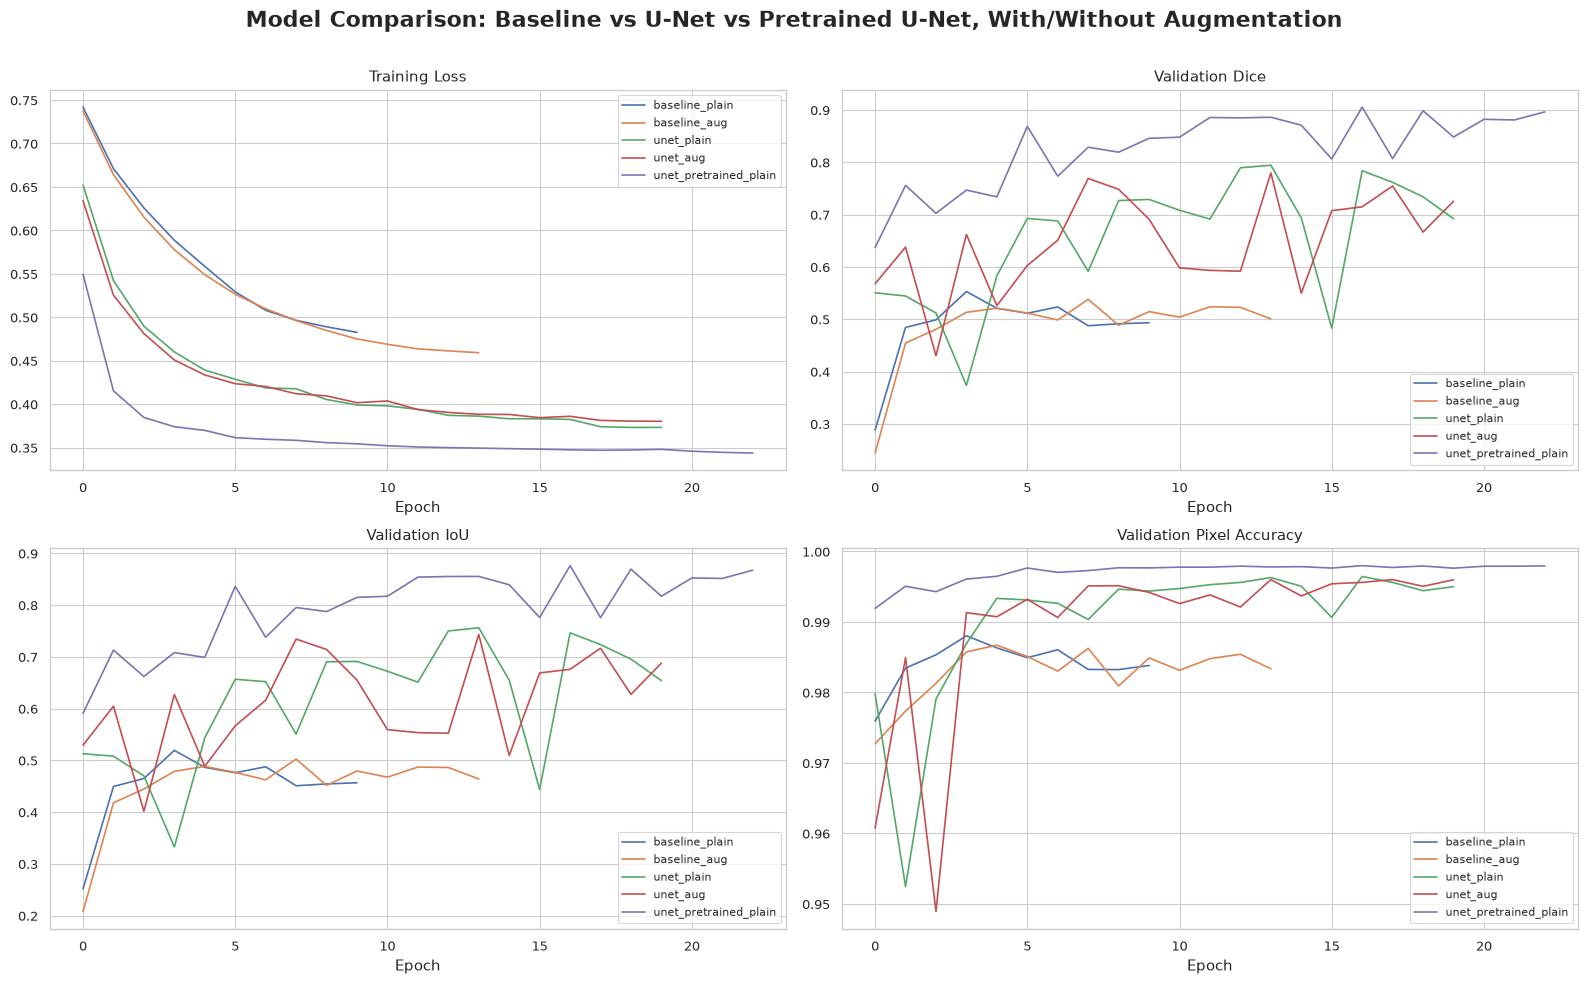

Saved comparison plot: results/training_comparison.png
Best model on test set: unet_pretrained_plain (Dice=0.9269)


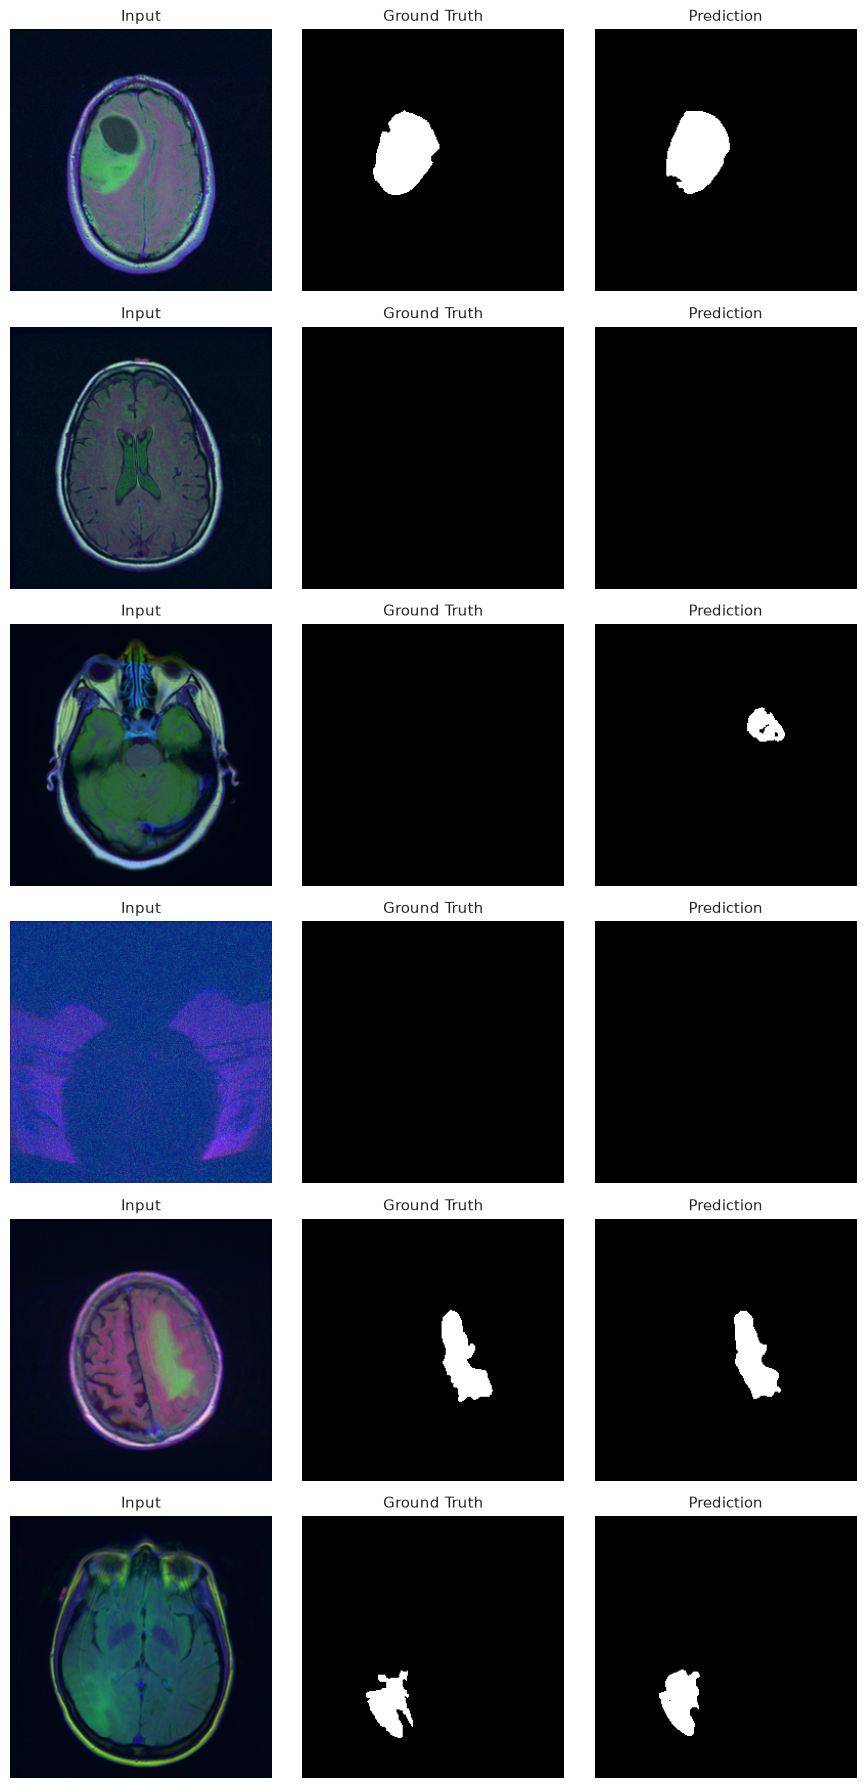

Saved prediction samples: results/predictions_unet_pretrained_plain.png


In [11]:

# %% [markdown]
# ## 8. Training loop

# %%
def train_model(model, name, train_loader, val_loader, device, epochs=25, lr=1e-3,
                 patience=6, ckpt_dir="checkpoints"):
    os.makedirs(ckpt_dir, exist_ok=True)
    model = model.to(device)
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    criterion = DiceBCELoss(bce_weight=0.5)
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

    history = {"train_loss": [], "val_dice": [], "val_iou": [], "val_precision": [],
               "val_recall": [], "val_pixel_acc": [], "lr": []}

    best_dice = -1.0
    epochs_no_improve = 0
    best_path = os.path.join(ckpt_dir, f"{name}_best.pt")

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        loop = tqdm(train_loader, desc=f"[{name}] Epoch {epoch+1}/{epochs}", leave=False)

        for imgs, masks in loop:
            imgs, masks = imgs.to(device), masks.to(device)
            opt.zero_grad()

            with torch.amp.autocast("cuda", enabled=(device == "cuda")):
                out = model(imgs)
                loss = criterion(out, masks)

            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(opt)
            scaler.update()

            total_loss += loss.item()
            loop.set_postfix(loss=loss.item())

        avg_loss = total_loss / len(train_loader)
        val_metrics = evaluate(model, val_loader, device)
        scheduler.step(val_metrics["dice"])
        current_lr = opt.param_groups[0]["lr"]

        history["train_loss"].append(avg_loss)
        history["val_dice"].append(val_metrics["dice"])
        history["val_iou"].append(val_metrics["iou"])
        history["val_precision"].append(val_metrics["precision"])
        history["val_recall"].append(val_metrics["recall"])
        history["val_pixel_acc"].append(val_metrics["pixel_acc"])
        history["lr"].append(current_lr)

        print(f"[{name}] Epoch {epoch+1}/{epochs} | loss={avg_loss:.4f} | "
              f"val_dice={val_metrics['dice']:.4f} | val_iou={val_metrics['iou']:.4f} | "
              f"val_acc={val_metrics['pixel_acc']:.4f} | lr={current_lr:.2e}")

        if val_metrics["dice"] > best_dice:
            best_dice = val_metrics["dice"]
            epochs_no_improve = 0
            torch.save(model.state_dict(), best_path)
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"[{name}] Early stopping at epoch {epoch+1} (no improvement for {patience} epochs)")
                break

    model.load_state_dict(torch.load(best_path))
    return model, history, best_dice

# %% [markdown]
# ## 9. Plotting helpers

# %%
def plot_comparison(all_histories, out_path="training_comparison.png"):
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle("Model Comparison: Baseline vs U-Net vs Pretrained U-Net, With/Without Augmentation",
                 fontsize=16, fontweight="bold")

    for name, hist in all_histories.items():
        axes[0, 0].plot(hist["train_loss"], label=name)
        axes[0, 1].plot(hist["val_dice"], label=name)
        axes[1, 0].plot(hist["val_iou"], label=name)
        axes[1, 1].plot(hist["val_pixel_acc"], label=name)

    axes[0, 0].set_title("Training Loss"); axes[0, 0].set_xlabel("Epoch"); axes[0, 0].legend(fontsize=8)
    axes[0, 1].set_title("Validation Dice"); axes[0, 1].set_xlabel("Epoch"); axes[0, 1].legend(fontsize=8)
    axes[1, 0].set_title("Validation IoU"); axes[1, 0].set_xlabel("Epoch"); axes[1, 0].legend(fontsize=8)
    axes[1, 1].set_title("Validation Pixel Accuracy"); axes[1, 1].set_xlabel("Epoch"); axes[1, 1].legend(fontsize=8)

    plt.tight_layout()
    fig.subplots_adjust(top=0.90)
    plt.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved comparison plot: {out_path}")


def visualize_predictions(model, dataset, device, thresh=0.5, use_blob_filter=False,
                           min_blob_size=20, n=6, out_path="predictions_sample.png"):
    model.eval()
    idxs = random.sample(range(len(dataset)), min(n, len(dataset)))
    fig, axes = plt.subplots(n, 3, figsize=(9, 3 * n))
    for row, idx in enumerate(idxs):
        img, mask = dataset[idx]
        with torch.no_grad():
            pred = torch.sigmoid(model(img.unsqueeze(0).to(device)))[0, 0].cpu().numpy()
        pred_bin = (pred > thresh).astype(np.float32)
        if use_blob_filter:
            pred_bin = remove_small_blobs(pred_bin, min_size=min_blob_size)

        img_show = img.permute(1, 2, 0).numpy()
        img_show = (img_show - img_show.min()) / (img_show.max() - img_show.min() + 1e-7)

        axes[row, 0].imshow(img_show); axes[row, 0].set_title("Input"); axes[row, 0].axis("off")
        axes[row, 1].imshow(mask[0].numpy(), cmap="gray"); axes[row, 1].set_title("Ground Truth"); axes[row, 1].axis("off")
        axes[row, 2].imshow(pred_bin, cmap="gray"); axes[row, 2].set_title("Prediction"); axes[row, 2].axis("off")

    plt.tight_layout()
    plt.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved prediction samples: {out_path}")

# %% [markdown]
# ## 10. Run all experiments
# 5 experiments now (pretrained U-Net added — FIX #2). This is the main
# cell that actually trains everything; it can take a while, so feel free
# to run experiments one at a time in separate cells if you want to inspect
# results between runs (see the "run one experiment" cell below as a template).

# %%
experiments = [
    ("baseline_plain", BaselineCNN(), train_loader_plain),
    ("baseline_aug", BaselineCNN(), train_loader_aug),
    ("unet_plain", UNet(), train_loader_plain),
    ("unet_aug", UNet(), train_loader_aug),
]
if not SKIP_PRETRAINED:
    experiments.append(("unet_pretrained_plain", build_pretrained_unet(), train_loader_plain))

all_histories = {}
final_results = {}
trained_models = {}
best_thresholds = {}

for name, model, loader in experiments:
    print(f"\n{'='*60}\nTraining: {name}\n{'='*60}")
    trained_model, history, best_val_dice = train_model(
        model, name, loader, val_loader, device,
        epochs=EPOCHS, ckpt_dir=os.path.join(OUT_DIR, "checkpoints"),
    )

    best_t, _ = find_best_threshold(trained_model, val_loader, device)
    best_thresholds[name] = best_t

    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    test_metrics = evaluate(trained_model, test_loader, device, thresh=best_t,
                             use_blob_filter=True, min_blob_size=MIN_BLOB_SIZE)

    all_histories[name] = history
    trained_models[name] = trained_model
    final_results[name] = {
        "best_val_dice": best_val_dice,
        "best_threshold": best_t,
        **{f"test_{k}": v for k, v in test_metrics.items()},
    }
    print(f"[{name}] best_threshold={best_t:.2f} | TEST metrics: {test_metrics}")

# %% [markdown]
# ### (Optional) Run just ONE experiment — e.g. to sanity-check the FIX #1
# mask-interpolation change on `unet_aug` alone before committing to a full run.

# %%
# name = "unet_aug"
# model = UNet()
# trained_model, history, best_val_dice = train_model(
#     model, name, train_loader_aug, val_loader, device,
#     epochs=EPOCHS, ckpt_dir=os.path.join(OUT_DIR, "checkpoints"),
# )
# best_t, _ = find_best_threshold(trained_model, val_loader, device)
# test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
# test_metrics = evaluate(trained_model, test_loader, device, thresh=best_t,
#                          use_blob_filter=True, min_blob_size=MIN_BLOB_SIZE)
# print(name, best_val_dice, test_metrics)

# %% [markdown]
# ## 11. Save results + plots

# %%
with open(os.path.join(OUT_DIR, "history_all_models.json"), "w") as f:
    json.dump(all_histories, f, indent=2)

results_df = pd.DataFrame(final_results).T
results_df.to_csv(os.path.join(OUT_DIR, "final_results_summary.csv"))
print("FINAL RESULTS SUMMARY (test set, tuned threshold + blob filter)")
results_df.round(4)

# %%
plot_comparison(all_histories, out_path=os.path.join(OUT_DIR, "training_comparison.png"))

# %%
best_model_name = max(final_results, key=lambda k: final_results[k]["test_dice"])
print(f"Best model on test set: {best_model_name} (Dice={final_results[best_model_name]['test_dice']:.4f})")

visualize_predictions(
    trained_models[best_model_name], test_ds, device,
    thresh=best_thresholds[best_model_name], use_blob_filter=True,
    min_blob_size=MIN_BLOB_SIZE,
    out_path=os.path.join(OUT_DIR, f"predictions_{best_model_name}.png"),
)

FINAL RESULTS SUMMARY (test set)
                       best_val_dice  best_threshold  test_dice  test_iou  test_precision  test_recall  test_pixel_acc
baseline_plain                0.5529            0.70     0.6841    0.6588          0.8837       0.7590          0.9918
baseline_aug                  0.5380            0.70     0.6485    0.6197          0.8123       0.7949          0.9909
unet_plain                    0.7944            0.70     0.8472    0.8105          0.8892       0.9086          0.9963
unet_aug                      0.7797            0.70     0.8154    0.7798          0.8919       0.8775          0.9958
unet_pretrained_plain         0.9053            0.65     0.9269    0.8993          0.9445       0.9473          0.9981


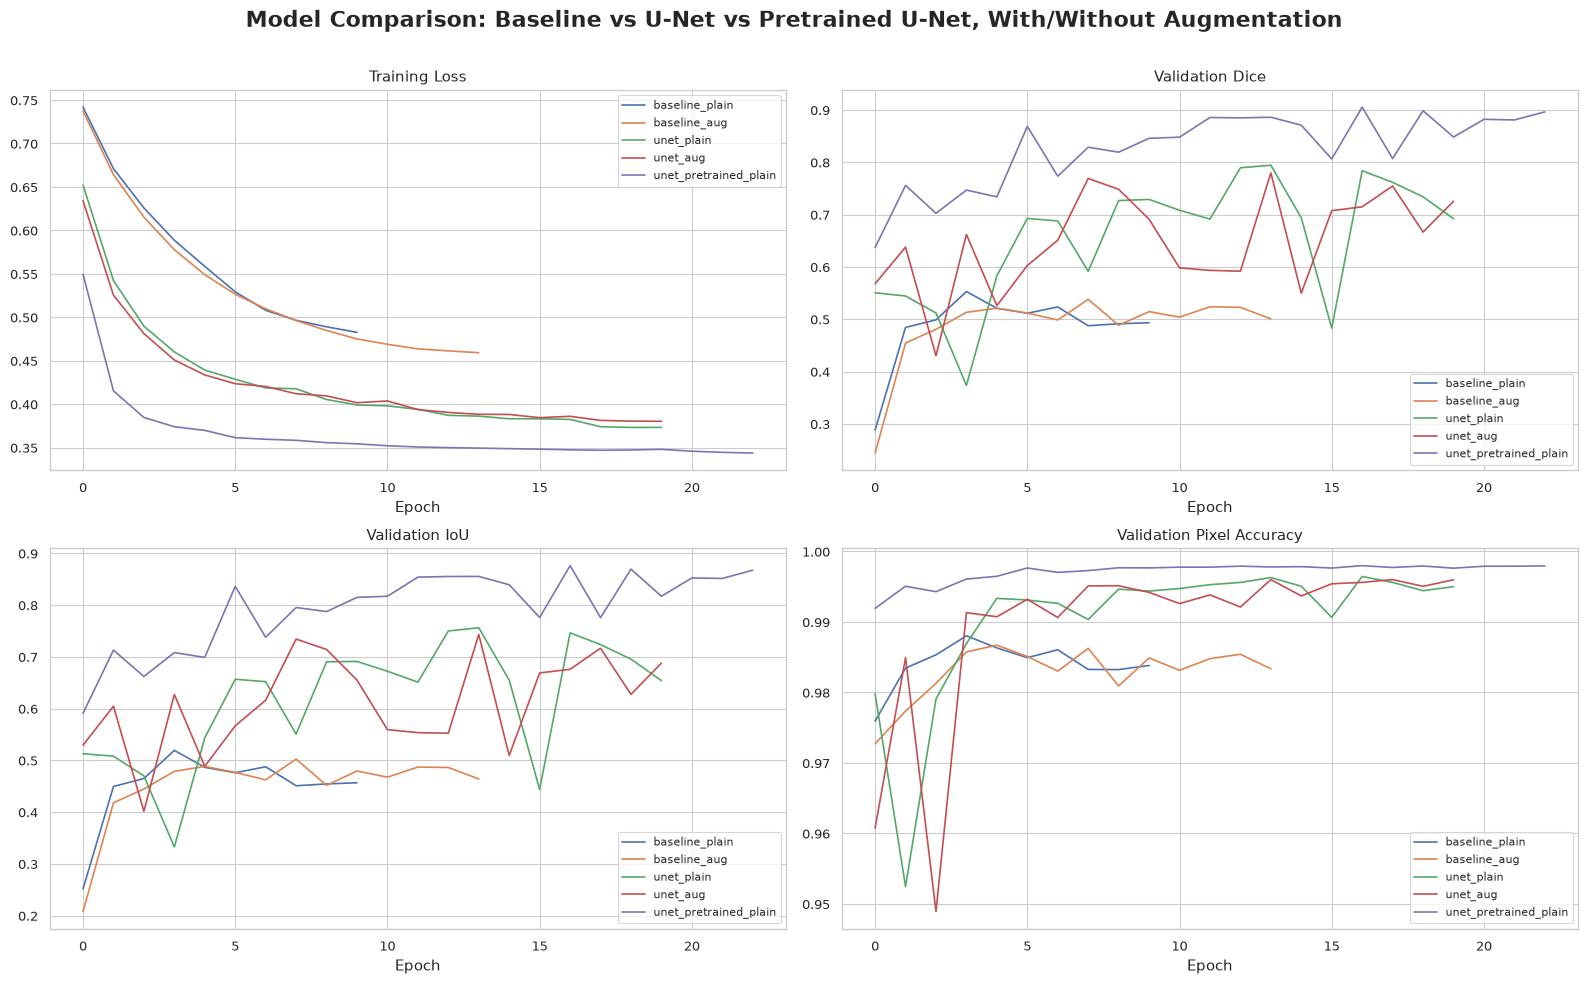

Saved comparison plot: results/training_comparison.png

Best model on test set: unet_pretrained_plain (Dice=0.9269)

OLD vs NEW COMPARISON
                old_test_dice  new_test_dice  delta_test_dice
baseline_plain         0.5726         0.6841           0.1115
baseline_aug           0.5394         0.6485           0.1091
unet_plain             0.8271         0.8472           0.0201
unet_aug               0.7209         0.8154           0.0945

New model not in old run: unet_pretrained_plain (Dice=0.9269)


In [12]:
# %% [markdown]
# ## Show results from a completed run
# Loads `final_results_summary.csv` and `history_all_models.json` from OUT_DIR
# and prints the same style of summary as your original run — no retraining.

# %%
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

OUT_DIR = "results"  # change if your results folder has a different name

# --- Load saved results ---
results_path = os.path.join(OUT_DIR, "final_results_summary.csv")
history_path = os.path.join(OUT_DIR, "history_all_models.json")

results_df = pd.read_csv(results_path, index_col=0)

with open(history_path, "r") as f:
    all_histories = json.load(f)

# --- Print summary exactly like the original run ---
print("=" * 60)
print("FINAL RESULTS SUMMARY (test set)")
print("=" * 60)
print(results_df.round(4).to_string())

# --- Rebuild comparison plot ---
def plot_comparison(all_histories, out_path="training_comparison.png"):
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle("Model Comparison: Baseline vs U-Net vs Pretrained U-Net, With/Without Augmentation",
                 fontsize=16, fontweight="bold")

    for name, hist in all_histories.items():
        axes[0, 0].plot(hist["train_loss"], label=name)
        axes[0, 1].plot(hist["val_dice"], label=name)
        axes[1, 0].plot(hist["val_iou"], label=name)
        axes[1, 1].plot(hist["val_pixel_acc"], label=name)

    axes[0, 0].set_title("Training Loss"); axes[0, 0].set_xlabel("Epoch"); axes[0, 0].legend(fontsize=8)
    axes[0, 1].set_title("Validation Dice"); axes[0, 1].set_xlabel("Epoch"); axes[0, 1].legend(fontsize=8)
    axes[1, 0].set_title("Validation IoU"); axes[1, 0].set_xlabel("Epoch"); axes[1, 0].legend(fontsize=8)
    axes[1, 1].set_title("Validation Pixel Accuracy"); axes[1, 1].set_xlabel("Epoch"); axes[1, 1].legend(fontsize=8)

    plt.tight_layout()
    fig.subplots_adjust(top=0.90)
    plt.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved comparison plot: {out_path}")


plot_comparison(all_histories, out_path=os.path.join(OUT_DIR, "training_comparison.png"))

# --- Best model line, same style as before ---
test_dice_col = "test_dice"
best_model_name = results_df[test_dice_col].astype(float).idxmax()
best_dice_val = results_df.loc[best_model_name, test_dice_col]
print(f"\nBest model on test set: {best_model_name} (Dice={float(best_dice_val):.4f})")

# %% [markdown]
# ### Before vs after comparison (old run vs new run)
# Paste your old numbers here to see the improvement side by side.

# %%
old_results = {
    "baseline_plain": {"test_dice": 0.5726, "test_iou": 0.5396, "test_precision": 0.7033, "test_recall": 0.8187, "test_pixel_acc": 0.9906},
    "baseline_aug":   {"test_dice": 0.5394, "test_iou": 0.5067, "test_precision": 0.6592, "test_recall": 0.8270, "test_pixel_acc": 0.9881},
    "unet_plain":     {"test_dice": 0.8271, "test_iou": 0.7906, "test_precision": 0.8587, "test_recall": 0.9204, "test_pixel_acc": 0.9967},
    "unet_aug":       {"test_dice": 0.7209, "test_iou": 0.6854, "test_precision": 0.7849, "test_recall": 0.8865, "test_pixel_acc": 0.9952},
}
old_df = pd.DataFrame(old_results).T

compare_cols = ["test_dice", "test_iou", "test_precision", "test_recall", "test_pixel_acc"]
common_models = [m for m in old_df.index if m in results_df.index]

comparison = pd.DataFrame(index=common_models)
for col in compare_cols:
    comparison[f"old_{col}"] = old_df.loc[common_models, col].astype(float)
    comparison[f"new_{col}"] = results_df.loc[common_models, col].astype(float)
    comparison[f"delta_{col}"] = comparison[f"new_{col}"] - comparison[f"old_{col}"]

print("\n" + "=" * 60)
print("OLD vs NEW COMPARISON")
print("=" * 60)
print(comparison[["old_test_dice", "new_test_dice", "delta_test_dice"]].round(4).to_string())

if "unet_pretrained_plain" in results_df.index:
    print(f"\nNew model not in old run: unet_pretrained_plain "
          f"(Dice={float(results_df.loc['unet_pretrained_plain', 'test_dice']):.4f})")

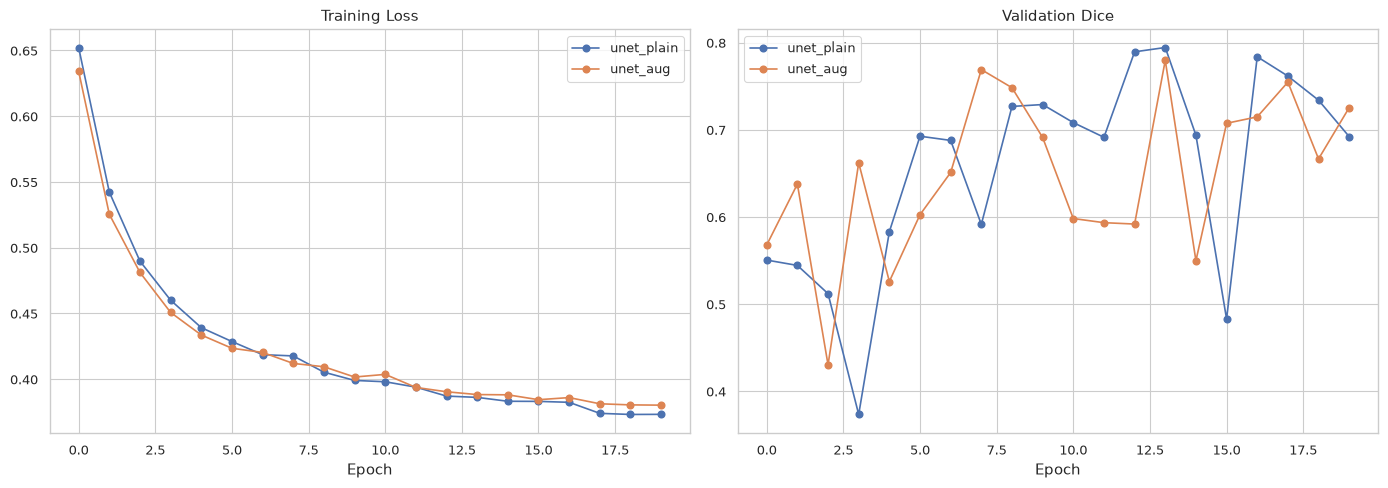

unet_plain ran 20 epochs before stopping
unet_aug ran 20 epochs before stopping


/storage/gpu_deeplearing/venv/lib/python3.11/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


[unet_aug_soft_longtrain] Epoch 1/40 | loss=0.6291 | val_dice=0.1463 | val_iou=0.1186 | val_acc=0.8213 | lr=1.00e-03


[unet_aug_soft_longtrain] Epoch 2/40 | loss=0.5243 | val_dice=0.6685 | val_iou=0.6341 | val_acc=0.9922 | lr=1.00e-03


[unet_aug_soft_longtrain] Epoch 3/40 | loss=0.4788 | val_dice=0.5277 | val_iou=0.4895 | val_acc=0.9832 | lr=1.00e-03


[unet_aug_soft_longtrain] Epoch 4/40 | loss=0.4525 | val_dice=0.5141 | val_iou=0.4743 | val_acc=0.9889 | lr=1.00e-03


... (22 outputs left out)

[unet_aug_soft_longtrain] Epoch 27/40 | loss=0.3814 | val_dice=0.7351 | val_iou=0.6978 | val_acc=0.9960 | lr=7.81e-06


[unet_aug_soft_longtrain] Epoch 28/40 | loss=0.3814 | val_dice=0.7145 | val_iou=0.6767 | val_acc=0.9958 | lr=7.81e-06


[unet_aug_soft_longtrain] Epoch 29/40 | loss=0.3802 | val_dice=0.7434 | val_iou=0.7063 | val_acc=0.9961 | lr=7.81e-06


[unet_aug_soft_longtrain] Epoch 30/40 | loss=0.3804 | val_dice=0.7418 | val_iou=0.7045 | val_acc=0.9961 | lr=3.91e-06
[unet_aug_soft_longtrain] Early stopping at epoch 30 (no improvement for 12 epochs)
[unet_aug_soft_longtrain] best_val_dice=0.7839 | best_threshold=0.70
[unet_aug_soft_longtrain] TEST metrics: {'dice': 0.8324010362302505, 'iou': 0.7969253704731653, 'precision': 0.8799072243795225, 'recall': 0.9057824395981111, 'pixel_acc': 0.9961655180333024}

Compare against:
  unet_plain   test_dice = 0.8472
  unet_aug     test_dice = 0.8154
  unet_aug_soft_longtrain test_dice = 0.8324
unet_plain: mean=0.8005  95% CI=[0.7716, 0.8270]
unet_aug:   mean=0.7836  95% CI=[0.7545, 0.8113]
-> CIs overlap: the gap may not be statistically robust from one run alone.


In [13]:
# %% [markdown]
# ## Diagnostic 1: did augmented training actually converge?
# Compares train_loss and val_dice curves epoch-by-epoch for the plain vs
# aug run of the SAME architecture. If the aug curve is still trending
# upward (val_dice) or downward (train_loss) when training stops, that's
# evidence it was cut off early rather than genuinely worse.

# %%
import matplotlib.pyplot as plt

def compare_convergence(all_histories, plain_name, aug_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(all_histories[plain_name]["train_loss"], label=plain_name, marker="o")
    axes[0].plot(all_histories[aug_name]["train_loss"], label=aug_name, marker="o")
    axes[0].set_title("Training Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()

    axes[1].plot(all_histories[plain_name]["val_dice"], label=plain_name, marker="o")
    axes[1].plot(all_histories[aug_name]["val_dice"], label=aug_name, marker="o")
    axes[1].set_title("Validation Dice"); axes[1].set_xlabel("Epoch"); axes[1].legend()

    plt.tight_layout()
    plt.show()

    n_plain = len(all_histories[plain_name]["val_dice"])
    n_aug = len(all_histories[aug_name]["val_dice"])
    print(f"{plain_name} ran {n_plain} epochs before stopping")
    print(f"{aug_name} ran {n_aug} epochs before stopping")
    if n_aug < n_plain:
        print(f"-> {aug_name} stopped {n_plain - n_aug} epochs earlier. "
              f"Check if its val_dice curve was still rising at cutoff — "
              f"if so, it likely needed more patience, not 'worse' augmentation.")

# Run this for whichever pair you want to inspect, e.g.:
compare_convergence(all_histories, "unet_plain", "unet_aug")
# compare_convergence(all_histories, "unet_pretrained_plain", "unet_pretrained_aug")


# %% [markdown]
# ## Diagnostic 2 / Fix attempt: re-run aug with more patience + softer augmentation
# Two changes at once, isolate later if this helps:
#  - epochs 25->40, patience 6->12 (gives aug more time to converge)
#  - ElasticTransform sigma raised (smoother, more realistic warps) and its
#    probability lowered; ShiftScaleRotate probability also lowered slightly
#  - This does NOT touch train_transform_plain or val_transform, so it's an
#    apples-to-apples test of "does augmentation help once given a fair shot"

# %%
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2

train_transform_aug_soft = A.Compose([
    A.Resize(height=IMG_SIZE, width=IMG_SIZE),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.3),
    A.ElasticTransform(alpha=80, sigma=120 * 0.10, p=0.2),   # smoother, less frequent
    A.ShiftScaleRotate(shift_limit=0.03, scale_limit=0.05, rotate_limit=10, p=0.4),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.2),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

train_ds_aug_soft = BrainMRIDataset(train_imgs, train_masks, transform=train_transform_aug_soft)
train_loader_aug_soft = DataLoader(train_ds_aug_soft, batch_size=BATCH_SIZE, shuffle=True,
                                    num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))

name = "unet_aug_soft_longtrain"
model = UNet()
trained_model, history, best_val_dice = train_model(
    model, name, train_loader_aug_soft, val_loader, device,
    epochs=40, patience=12, ckpt_dir=os.path.join(OUT_DIR, "checkpoints"),
)

best_t, _ = find_best_threshold(trained_model, val_loader, device)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_metrics = evaluate(trained_model, test_loader, device, thresh=best_t,
                         use_blob_filter=True, min_blob_size=MIN_BLOB_SIZE)

print(f"[{name}] best_val_dice={best_val_dice:.4f} | best_threshold={best_t:.2f}")
print(f"[{name}] TEST metrics: {test_metrics}")
print(f"\nCompare against:")
print(f"  unet_plain   test_dice = {final_results['unet_plain']['test_dice']:.4f}")
print(f"  unet_aug     test_dice = {final_results['unet_aug']['test_dice']:.4f}")
print(f"  {name} test_dice = {test_metrics['dice']:.4f}")

# merge in if you want it in the results table
all_histories[name] = history
final_results[name] = {
    "best_val_dice": best_val_dice, "best_threshold": best_t,
    **{f"test_{k}": v for k, v in test_metrics.items()},
}


# %% [markdown]
# ## Diagnostic 3: is the gap even statistically meaningful?
# Bootstraps the per-image Dice scores on the test set to get a rough
# confidence interval. If the plain-vs-aug CIs overlap a lot, the "gap"
# in your single-run numbers may just be noise.

# %%
import numpy as np

@torch.no_grad()
def per_image_dice(model, dataset, device, thresh=0.5, batch_size=32):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    model.eval()
    dices = []
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        preds = (torch.sigmoid(model(imgs)) > thresh).float()
        tp = (preds * masks).sum(dim=(1, 2, 3))
        fp = (preds * (1 - masks)).sum(dim=(1, 2, 3))
        fn = ((1 - preds) * masks).sum(dim=(1, 2, 3))
        dice = (2 * tp + 1e-7) / (2 * tp + fp + fn + 1e-7)
        dices.extend(dice.cpu().tolist())
    return np.array(dices)


def bootstrap_ci(scores, n_boot=2000, ci=95):
    boots = [np.mean(np.random.choice(scores, size=len(scores), replace=True))
             for _ in range(n_boot)]
    lo = np.percentile(boots, (100 - ci) / 2)
    hi = np.percentile(boots, 100 - (100 - ci) / 2)
    return np.mean(scores), lo, hi


# requires trained_models["unet_plain"] and trained_models["unet_aug"] to exist
plain_dices = per_image_dice(trained_models["unet_plain"], test_ds, device)
aug_dices = per_image_dice(trained_models["unet_aug"], test_ds, device)

mean_p, lo_p, hi_p = bootstrap_ci(plain_dices)
mean_a, lo_a, hi_a = bootstrap_ci(aug_dices)

print(f"unet_plain: mean={mean_p:.4f}  95% CI=[{lo_p:.4f}, {hi_p:.4f}]")
print(f"unet_aug:   mean={mean_a:.4f}  95% CI=[{lo_a:.4f}, {hi_a:.4f}]")
if hi_a > lo_p:
    print("-> CIs overlap: the gap may not be statistically robust from one run alone.")
else:
    print("-> CIs do NOT overlap: this looks like a real, reproducible effect.")

In [15]:
# %% [markdown]
# ## If `trained_model` in memory no longer holds unet_aug_soft_longtrain,
# reload its weights from the saved checkpoint instead.

# %%
import torch

reload_model = UNet().to(device)
ckpt_path = os.path.join(OUT_DIR, "checkpoints", "unet_aug_soft_longtrain_best.pt")
reload_model.load_state_dict(torch.load(ckpt_path, map_location=device))
trained_models["unet_aug_soft_longtrain"] = reload_model

print(f"Reloaded unet_aug_soft_longtrain from {ckpt_path}")

Reloaded unet_aug_soft_longtrain from results/checkpoints/unet_aug_soft_longtrain_best.pt


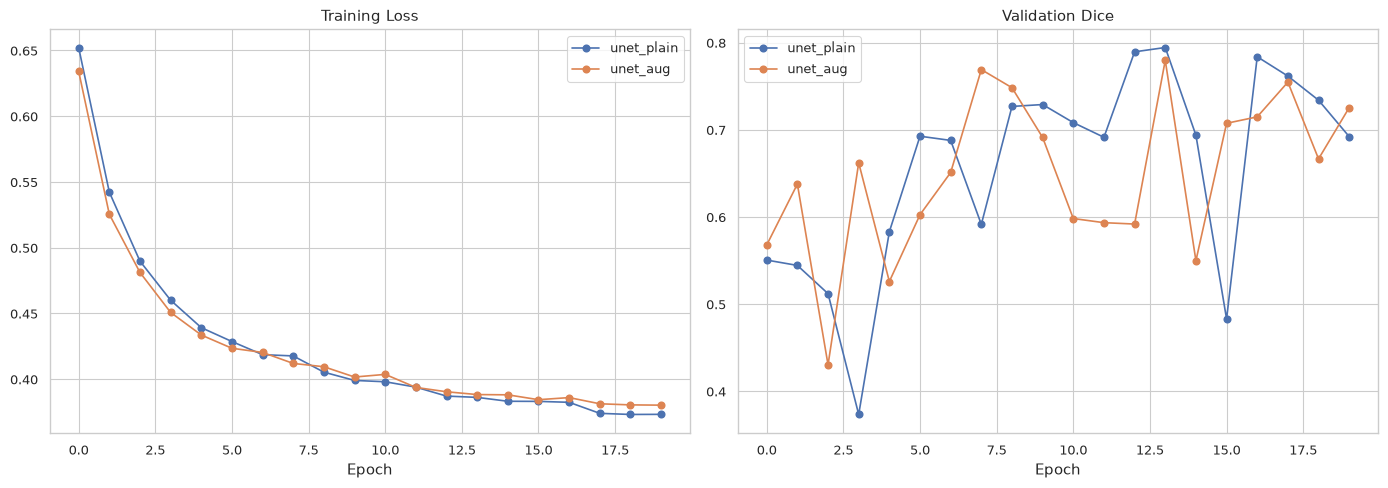

unet_plain ran 20 epochs before stopping
unet_aug ran 20 epochs before stopping


[unet_aug_soft_longtrain] Epoch 1/40 | loss=0.6563 | val_dice=0.6902 | val_iou=0.6594 | val_acc=0.9888 | lr=1.00e-03


[unet_aug_soft_longtrain] Epoch 2/40 | loss=0.5390 | val_dice=0.1289 | val_iou=0.0994 | val_acc=0.8106 | lr=1.00e-03


[unet_aug_soft_longtrain] Epoch 3/40 | loss=0.4852 | val_dice=0.6552 | val_iou=0.6222 | val_acc=0.9898 | lr=1.00e-03


[unet_aug_soft_longtrain] Epoch 4/40 | loss=0.4556 | val_dice=0.5481 | val_iou=0.5118 | val_acc=0.9771 | lr=5.00e-04


[unet_aug_soft_longtrain] Epoch 5/40 | loss=0.4356 | val_dice=0.6648 | val_iou=0.6284 | val_acc=0.9932 | lr=5.00e-04


... (23 outputs left out)

[unet_aug_soft_longtrain] Epoch 29/40 | loss=0.3767 | val_dice=0.7171 | val_iou=0.6814 | val_acc=0.9959 | lr=7.81e-06


[unet_aug_soft_longtrain] Epoch 30/40 | loss=0.3766 | val_dice=0.7511 | val_iou=0.7156 | val_acc=0.9963 | lr=7.81e-06


[unet_aug_soft_longtrain] Epoch 31/40 | loss=0.3758 | val_dice=0.7658 | val_iou=0.7307 | val_acc=0.9965 | lr=7.81e-06


[unet_aug_soft_longtrain] Epoch 32/40 | loss=0.3752 | val_dice=0.7685 | val_iou=0.7337 | val_acc=0.9964 | lr=3.91e-06
[unet_aug_soft_longtrain] Early stopping at epoch 32 (no improvement for 12 epochs)
[unet_aug_soft_longtrain] best_val_dice=0.7845 | best_threshold=0.70
[unet_aug_soft_longtrain] TEST metrics: {'dice': 0.8296238310792758, 'iou': 0.7931530200734046, 'precision': 0.868217827895797, 'recall': 0.9126494213355282, 'pixel_acc': 0.9964971251406912}

Compare against:
  unet_plain   test_dice = 0.8472
  unet_aug     test_dice = 0.8154
  unet_aug_soft_longtrain test_dice = 0.8296
unet_plain: mean=0.8005  95% CI=[0.7717, 0.8273]
unet_aug:   mean=0.7836  95% CI=[0.7548, 0.8121]
-> CIs overlap: the gap may not be statistically robust from one run alone.


In [16]:
# %% [markdown]
# ## Diagnostic 1: did augmented training actually converge?
# Compares train_loss and val_dice curves epoch-by-epoch for the plain vs
# aug run of the SAME architecture. If the aug curve is still trending
# upward (val_dice) or downward (train_loss) when training stops, that's
# evidence it was cut off early rather than genuinely worse.

# %%
import matplotlib.pyplot as plt

def compare_convergence(all_histories, plain_name, aug_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(all_histories[plain_name]["train_loss"], label=plain_name, marker="o")
    axes[0].plot(all_histories[aug_name]["train_loss"], label=aug_name, marker="o")
    axes[0].set_title("Training Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()

    axes[1].plot(all_histories[plain_name]["val_dice"], label=plain_name, marker="o")
    axes[1].plot(all_histories[aug_name]["val_dice"], label=aug_name, marker="o")
    axes[1].set_title("Validation Dice"); axes[1].set_xlabel("Epoch"); axes[1].legend()

    plt.tight_layout()
    plt.show()

    n_plain = len(all_histories[plain_name]["val_dice"])
    n_aug = len(all_histories[aug_name]["val_dice"])
    print(f"{plain_name} ran {n_plain} epochs before stopping")
    print(f"{aug_name} ran {n_aug} epochs before stopping")
    if n_aug < n_plain:
        print(f"-> {aug_name} stopped {n_plain - n_aug} epochs earlier. "
              f"Check if its val_dice curve was still rising at cutoff — "
              f"if so, it likely needed more patience, not 'worse' augmentation.")

# Run this for whichever pair you want to inspect, e.g.:
compare_convergence(all_histories, "unet_plain", "unet_aug")
# compare_convergence(all_histories, "unet_pretrained_plain", "unet_pretrained_aug")


# %% [markdown]
# ## Diagnostic 2 / Fix attempt: re-run aug with more patience + softer augmentation
# Two changes at once, isolate later if this helps:
#  - epochs 25->40, patience 6->12 (gives aug more time to converge)
#  - ElasticTransform sigma raised (smoother, more realistic warps) and its
#    probability lowered; ShiftScaleRotate probability also lowered slightly
#  - This does NOT touch train_transform_plain or val_transform, so it's an
#    apples-to-apples test of "does augmentation help once given a fair shot"

# %%
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2

train_transform_aug_soft = A.Compose([
    A.Resize(height=IMG_SIZE, width=IMG_SIZE),
    A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.3),
    A.ElasticTransform(alpha=80, sigma=120 * 0.10, p=0.2),   # smoother, less frequent
    A.ShiftScaleRotate(shift_limit=0.03, scale_limit=0.05, rotate_limit=10, p=0.4),
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.2),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

train_ds_aug_soft = BrainMRIDataset(train_imgs, train_masks, transform=train_transform_aug_soft)
train_loader_aug_soft = DataLoader(train_ds_aug_soft, batch_size=BATCH_SIZE, shuffle=True,
                                    num_workers=NUM_WORKERS, pin_memory=(device == "cuda"))

name = "unet_aug_soft_longtrain"
model = UNet()
trained_model, history, best_val_dice = train_model(
    model, name, train_loader_aug_soft, val_loader, device,
    epochs=40, patience=12, ckpt_dir=os.path.join(OUT_DIR, "checkpoints"),
)

best_t, _ = find_best_threshold(trained_model, val_loader, device)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_metrics = evaluate(trained_model, test_loader, device, thresh=best_t,
                         use_blob_filter=True, min_blob_size=MIN_BLOB_SIZE)

print(f"[{name}] best_val_dice={best_val_dice:.4f} | best_threshold={best_t:.2f}")
print(f"[{name}] TEST metrics: {test_metrics}")
print(f"\nCompare against:")
print(f"  unet_plain   test_dice = {final_results['unet_plain']['test_dice']:.4f}")
print(f"  unet_aug     test_dice = {final_results['unet_aug']['test_dice']:.4f}")
print(f"  {name} test_dice = {test_metrics['dice']:.4f}")

# merge in if you want it in the results table
all_histories[name] = history
trained_models[name] = trained_model  # <- this line was missing, needed for later bootstrap/viz use
final_results[name] = {
    "best_val_dice": best_val_dice, "best_threshold": best_t,
    **{f"test_{k}": v for k, v in test_metrics.items()},
}


# %% [markdown]
# ## Diagnostic 3: is the gap even statistically meaningful?
# Bootstraps the per-image Dice scores on the test set to get a rough
# confidence interval. If the plain-vs-aug CIs overlap a lot, the "gap"
# in your single-run numbers may just be noise.

# %%
import numpy as np

@torch.no_grad()
def per_image_dice(model, dataset, device, thresh=0.5, batch_size=32):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    model.eval()
    dices = []
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        preds = (torch.sigmoid(model(imgs)) > thresh).float()
        tp = (preds * masks).sum(dim=(1, 2, 3))
        fp = (preds * (1 - masks)).sum(dim=(1, 2, 3))
        fn = ((1 - preds) * masks).sum(dim=(1, 2, 3))
        dice = (2 * tp + 1e-7) / (2 * tp + fp + fn + 1e-7)
        dices.extend(dice.cpu().tolist())
    return np.array(dices)


def bootstrap_ci(scores, n_boot=2000, ci=95):
    boots = [np.mean(np.random.choice(scores, size=len(scores), replace=True))
             for _ in range(n_boot)]
    lo = np.percentile(boots, (100 - ci) / 2)
    hi = np.percentile(boots, 100 - (100 - ci) / 2)
    return np.mean(scores), lo, hi


# requires trained_models["unet_plain"] and trained_models["unet_aug"] to exist
plain_dices = per_image_dice(trained_models["unet_plain"], test_ds, device)
aug_dices = per_image_dice(trained_models["unet_aug"], test_ds, device)

mean_p, lo_p, hi_p = bootstrap_ci(plain_dices)
mean_a, lo_a, hi_a = bootstrap_ci(aug_dices)

print(f"unet_plain: mean={mean_p:.4f}  95% CI=[{lo_p:.4f}, {hi_p:.4f}]")
print(f"unet_aug:   mean={mean_a:.4f}  95% CI=[{lo_a:.4f}, {hi_a:.4f}]")
if hi_a > lo_p:
    print("-> CIs overlap: the gap may not be statistically robust from one run alone.")
else:
    print("-> CIs do NOT overlap: this looks like a real, reproducible effect.")

In [5]:
# %% [markdown]
# ## Run just unet_pretrained_aug (standalone)
# Use this if you already trained the other experiments and only want to
# add the pretrained + augmented U-Net without re-running everything.

# %%
name = "unet_pretrained_aug"
model = build_pretrained_unet()

trained_model, history, best_val_dice = train_model(
    model, name, train_loader_aug, val_loader, device,
    epochs=EPOCHS, ckpt_dir=os.path.join(OUT_DIR, "checkpoints"),
)

best_t, _ = find_best_threshold(trained_model, val_loader, device)

test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_metrics = evaluate(trained_model, test_loader, device, thresh=best_t,
                         use_blob_filter=True, min_blob_size=MIN_BLOB_SIZE)

print(f"[{name}] best_val_dice={best_val_dice:.4f} | best_threshold={best_t:.2f}")
print(f"[{name}] TEST metrics: {test_metrics}")

# --- Merge into existing results dicts (if they already exist from a prior run) ---
all_histories[name] = history
trained_models[name] = trained_model
best_thresholds[name] = best_t
final_results[name] = {
    "best_val_dice": best_val_dice,
    "best_threshold": best_t,
    **{f"test_{k}": v for k, v in test_metrics.items()},
}

# --- Re-save the combined results/history so the CSV/JSON stay complete ---
with open(os.path.join(OUT_DIR, "history_all_models.json"), "w") as f:
    json.dump(all_histories, f, indent=2)

results_df = pd.DataFrame(final_results).T
results_df.to_csv(os.path.join(OUT_DIR, "final_results_summary.csv"))
print("\nUpdated results:")
print(results_df.round(4).to_string())

[unet_pretrained_aug] Epoch 1/25 | loss=0.5451 | val_dice=0.7698 | val_iou=0.7278 | val_acc=0.9938 | lr=1.00e-03


[unet_pretrained_aug] Epoch 2/25 | loss=0.4133 | val_dice=0.6778 | val_iou=0.6397 | val_acc=0.9937 | lr=1.00e-03


[unet_pretrained_aug] Epoch 3/25 | loss=0.3897 | val_dice=0.6372 | val_iou=0.6015 | val_acc=0.9938 | lr=1.00e-03


[unet_pretrained_aug] Epoch 4/25 | loss=0.3805 | val_dice=0.6600 | val_iou=0.6224 | val_acc=0.9952 | lr=5.00e-04


[unet_pretrained_aug] Epoch 5/25 | loss=0.3716 | val_dice=0.8774 | val_iou=0.8451 | val_acc=0.9971 | lr=5.00e-04


[unet_pretrained_aug] Epoch 6/25 | loss=0.3679 | val_dice=0.8137 | val_iou=0.7797 | val_acc=0.9971 | lr=5.00e-04


[unet_pretrained_aug] Epoch 7/25 | loss=0.3673 | val_dice=0.7358 | val_iou=0.7025 | val_acc=0.9970 | lr=5.00e-04


[unet_pretrained_aug] Epoch 8/25 | loss=0.3676 | val_dice=0.7938 | val_iou=0.7607 | val_acc=0.9970 | lr=2.50e-04


[unet_pretrained_aug] Epoch 9/25 | loss=0.3634 | val_dice=0.8400 | val_iou=0.8084 | val_acc=0.9976 | lr=2.50e-04


[unet_pretrained_aug] Epoch 10/25 | loss=0.3622 | val_dice=0.7051 | val_iou=0.6723 | val_acc=0.9971 | lr=2.50e-04


[unet_pretrained_aug] Epoch 11/25 | loss=0.3617 | val_dice=0.7778 | val_iou=0.7442 | val_acc=0.9972 | lr=1.25e-04
[unet_pretrained_aug] Early stopping at epoch 11 (no improvement for 6 epochs)
[unet_pretrained_aug] best_val_dice=0.8774 | best_threshold=0.70
[unet_pretrained_aug] TEST metrics: {'dice': 0.8918569775154279, 'iou': 0.8610160944018578, 'precision': 0.9133315737248383, 'recall': 0.9360421934051358, 'pixel_acc': 0.997464325468419}

Updated results:
                       best_val_dice  best_threshold  test_dice  test_iou  test_precision  test_recall  test_pixel_acc
baseline_plain                0.5529             0.7     0.6841    0.6588          0.8837       0.7590          0.9918
baseline_aug                  0.5171             0.7     0.6392    0.6146          0.8327       0.7606          0.9911
unet_plain                    0.7475             0.7     0.7878    0.7478          0.8957       0.8359          0.9935
unet_aug                      0.7303             0.7     0.76